In [1]:

from turtle import delay
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from Models_MLP_tuning_orig import MLP_aif, MLP_myo, MLP_ode
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
from tqdm import tqdm
from torch.optim.lr_scheduler import ReduceLROnPlateau, OneCycleLR
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torcheval.metrics import MeanSquaredError as mse_metric
from random import randint, random
from itertools import cycle
from Create_DRO_2 import make_dro_no_delay
import time
from soap import SOAP

%matplotlib inline

In [2]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

2.5.1
11.8
True


In [3]:
if torch.cuda.is_available():
    device = torch.device("cuda")  # Windows/Linux
    print("gpuuuuuuuuu")

elif torch.backends.mps.is_available():
    device = torch.device("mps")  # MacOS
else:
    device = torch.device("cpu")
    print("cpuuuuu")

gpuuuuuuuuu


In [4]:
def phys_params_to_tt_params_torch(f, vp, ve, ps):

    f, vp, ve, ps = f.to(device), vp.to(device), ve.to(device), ps.to(device)
    tb = vp / f
    tp = vp / (ps + f)
    te = ve / ps

    return tb, tp, te


def tt_params_to_model_params_torch(tb, tp, te):

    tb, tp, te = tb.to(device), tp.to(device), te.to(device)
    k_m = 0.5 * (
        1.0 / tp
        + 1.0 / te
        - torch.sqrt((1.0 / tp + 1.0 / te) ** 2 - 4.0 * (1.0 / tb) * (1.0 / te))
    )
    k_p = 0.5 * ( 1.0 / tp + 1.0 / te + torch.sqrt((1.0 / tp + 1.0 / te) ** 2 - 4.0 * (1.0 / tb) * (1.0 / te))
    )
    d = k_p - k_m
    e = (k_p - 1.0 / tb) / d

    return d, e, k_m

In [5]:
def two_CXM_torch(
    parameters: torch.Tensor, time: torch.Tensor, aif: torch.Tensor, dt: float
) -> torch.Tensor:
    """
    parameters: [N, 4] → Fp, vp, ve, PS
    time: [T] → shared time vector
    aif: [T] or [1,1,T]
    dt: scalar
    returns: [N, T] → modeled tissue curve per voxel
    """
    thres_1 = 1e-4
    thres_2 = 3
    parameters = parameters.to(device)
    N, T = parameters.shape[0], time.shape[-1]
    flow = parameters[..., 0]
    vp = parameters[..., 1]
    ve = parameters[..., 2]
    ps = parameters[..., 3]
    tb, tp, te = phys_params_to_tt_params_torch(flow, vp, ve, ps)
    d, e, km = tt_params_to_model_params_torch(tb, tp, te)

    time = time.clone().detach().to(device).reshape(1, 1, -1)
    aif = aif.clone().detach().to(device).reshape(1, 1, -1)

    exp1 = torch.exp(-km[..., None] * time)  # [1, T]
    exp2 = torch.exp(-(km[..., None] + d[..., None]) * time)  # [1, T]

    aif = torch.flip(aif, dims=[-1])
    # Batched convolution
    conv1 = F.conv1d(exp1, aif, padding=T - 1)
    conv2 = F.conv1d(exp2, aif, padding=T - 1)
    
    conv = flow[:, :, None] * dt * (e[:, :, None] * conv1 + (1 - e[:, :, None]) * conv2)[..., :T]

    return conv

In [ ]:
def train_pinn(
    myo_curves, myo_pars, aif_time, aif,
    epochs=3000, lr=1e-4, batch_size=256, seed_value=42,
    num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
    num_layers_myo=5, dim_hidden_myo=128, w0_myo=20, w0_initial_myo=25,
    num_layers_2cxm=4, dim_hidden_2cxm=256,w0_2cxm=10, w0_initial_2cxm=20,
    loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_ode_p = 0.01, loss_w_ode_e = 1.0, loss_w_2cxm=10.0,
    lr_adam_aif=3e-5, #param that yields TFL=200 at 300 epochs,
    alpha=0.5
):

    """
    PINN training function where myocardial concentration is modeled as:

        C_myo = v_e * C_e + v_p * C_p

    model_e predicts C_e
    model_p predicts C_p

    myo_pars[..., 1] = v_p
    myo_pars[..., 2] = v_e
    """

    # myo_curves shape: [T, H, W, 1]
    # myo_pars shape:   [H, W, 1, 4]

    T, H, W, _ = myo_curves.shape
    N = H * W

    print(f"Shape of myo_curves: {myo_curves.shape}")
    print(f"Shape of myo_pars: {myo_pars.shape}")
    print("Shape of aif_time, min, max: {}, {}, {}".format(aif_time.shape, min(aif_time),
                                                           max(aif_time))) 
    t_norm = np.arange(0, 2, 2/100).astype(np.float32)
    print("Shape of t_norm, min, max: {}, {}, {}".format(t_norm.shape, min(t_norm),
                                                           max(t_norm)))

    # =========================
    # Time and coordinate tensors
    # =========================
    t = torch.tensor(aif_time, dtype=torch.float32).to(device)
    dt = aif_time[1] - aif_time[0]

    x = np.linspace(0, 1, H).astype(np.float32)
    y = np.linspace(0, 1, W).astype(np.float32)

    # Normalized time for MYO model input
    t_norm = aif_time # np.arange(0, 2, 2/100).astype(np.float32) #np.linspace(0, 2, T).astype(np.float32)

    xx_ode, yy_ode = np.meshgrid(x, y, indexing="ij") # [H,W]
    coords_ode = np.stack([xx_ode, yy_ode], axis=-1).reshape(-1, 2) # [H*W, 2]
    X_tensor_ode = torch.tensor(coords_ode, dtype=torch.float32).to(device) 
    # the same coordinates, will be used for visualization reasons only to distinguish ode from myo

    tt, xx, yy = np.meshgrid(t_norm, x, y, indexing="ij") # [T,H,W]
    coords_txy = np.stack([tt, xx, yy], axis=-1).reshape(-1, 3)  # [T*H*W,3]
    intensities = myo_curves[..., 0].reshape(-1, 1)              # [T*H*W,1]

    X_tensor_myo = torch.tensor(coords_txy, dtype=torch.float32).to(device)
    Y_tensor_myo = torch.tensor(intensities, dtype=torch.float32).to(device)

    # =========================
    # AIF tensors
    # =========================
    t_tensor_aif = torch.tensor(aif_time.reshape(-1, 1),dtype=torch.float32).to(device)
    Y_tensor_aif = torch.tensor(aif.reshape(-1, 1),dtype=torch.float32).to(device)

    #del
    #print(t_tensor_aif)

    # =========================
    # Reshape MYO data by voxel
    # =========================
    X_grouped = X_tensor_myo.view(T, H * W, 3).permute(1, 0, 2)  # [N,T,3]
    Y_grouped = Y_tensor_myo.view(T, H * W, 1).permute(1, 0, 2)  # [N,T,1]

    # =========================
    # Extract vp and ve
    # =========================

    dataset_myo = TensorDataset(
        X_grouped,
        Y_grouped
    )

    loader_myo = DataLoader(
        dataset_myo,
        batch_size=batch_size,
        shuffle=True       ######## should be True
    )

    # =========================
    # Models
    # =========================
    torch.manual_seed(seed=seed_value) #seed=seed_value

    model_aif = MLP_aif(
        num_layers_aif,
        dim_hidden_aif,
        dim_in=1,
        dim_out=1,
        w0_aif=w0_aif,
        w0_initial_aif=w0_initial_aif,
        final_activation=None
    ).to(device)

    model_e = MLP_myo(
        num_layers_myo,
        dim_hidden_myo,
        dim_in=3,
        dim_out=1,
        w0_myo=w0_myo,
        w0_initial_myo=w0_initial_myo,
        final_activation=None
    ).to(device)

    model_p = MLP_myo(
        num_layers_myo,
        dim_hidden_myo,
        dim_in=3,
        dim_out=1,
        w0_myo=w0_myo,
        w0_initial_myo=w0_initial_myo,
        final_activation=None
    ).to(device)

    model_ode = MLP_ode(
        num_layers_2cxm,
        dim_hidden_2cxm,
        dim_in=2,
        dim_out=4,
        w0_2cxm=w0_2cxm,
        w0_initial_2cxm=w0_initial_2cxm,
        final_activation=nn.Softplus()
      ).to(device)

    # =========================
    # Optimizers and loss
    # =========================

    optimizer_aif = optim.Adam(model_aif.parameters(), lr=3e-5)
    optimizer_e = SOAP(model_e.parameters(), lr=3e-5) #, betas=betas_e
    optimizer_p = SOAP(model_p.parameters(), lr=1e-4) # betas=betas_p
    optimizer_ode = SOAP(model_ode.parameters(), lr=2e-4) #betas=betas_ode

    criterion_aif = nn.HuberLoss(delta=10.0) #tuned 
    criterion_myo = nn.HuberLoss(delta=0.01) #tuned
    criterion_ode = nn.HuberLoss(delta=0.01) #tuned

    ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

    #following two lines copied for ode implant
    myo_eval = torch.tensor(myo_curves, dtype=torch.float32).squeeze(-1).to(device)
    ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)

    total_losses = []
    cost_array = np.zeros((epochs, 4))

    # =========================
    # Training loop
    # =========================
    
    for epoch in tqdm(range(epochs)):

        # if epoch==300:
        #     print("here")
        #     lr_soap_p_new = 3e-5
        #     optimizer_p = SOAP(model_p.parameters(), lr=lr_soap_p_new) # betas=betas_p
        #     lr_soap_e_new = 3e-5
        #     optimizer_e = SOAP(model_e.parameters(), lr=lr_soap_e_new) #, betas=betas_e
        #     lr_soap_ode_new = 3e-5
        #     optimizer_ode = SOAP(model_ode.parameters(), lr=lr_soap_ode_new) #betas=betas_ode

        if epoch==1000:
            print("here")
            lr_soap_p_new = 3e-5
            optimizer_p = SOAP(model_p.parameters(), lr=lr_soap_p_new) # betas=betas_p
            lr_soap_e_new = 3e-5
            optimizer_e = SOAP(model_e.parameters(), lr=lr_soap_e_new) #, betas=betas_e
            lr_soap_ode_new = 3e-5
            optimizer_ode = SOAP(model_ode.parameters(), lr=lr_soap_ode_new) #betas=betas_ode

        model_aif.train()
        model_e.train()
        model_p.train()
        model_ode.train()

        total_epoch_loss = 0.0

        i = 0
        for X_myo_batch, Y_myo_batch in loader_myo:

            optimizer_aif.zero_grad()
            optimizer_e.zero_grad()
            optimizer_p.zero_grad()
            optimizer_ode.zero_grad()

            X_myo_batch = X_myo_batch.to(device)
            Y_myo_batch = Y_myo_batch.to(device)
            #voxel_id_batch = voxel_id_batch.squeeze(-1).to(device)

            B, T_batch, _ = X_myo_batch.shape

            #t_input = X_myo_batch[..., :1].reshape(-1, 1)   # [B*T,1]
            t_input = X_myo_batch[..., :1].reshape(-1, 1).clone().detach().requires_grad_(True)   # [B*T,1]
            xy_input = X_myo_batch[..., 1:].reshape(-1, 2)  # [B*T,2]

            Y_target = Y_myo_batch.view(B, T_batch)         # [B,T]

            # =========================
            # AIF prediction and loss
            # =========================
            pred_aif = model_aif(t_tensor_aif)              # [T,1]
            loss_aif = criterion_aif(pred_aif, Y_tensor_aif)

            # =========================
            # Predict C_e and C_p
            # =========================
            pred_e = model_e(t_input, xy_input)             # [B*T,1]
            pred_p = model_p(t_input, xy_input)             # [B*T,1]

            C_e = pred_e.view(B, T_batch)                   # [B,T]
            C_p = pred_p.view(B, T_batch)                   # [B,T]


            xy_coords = X_myo_batch[:, 0, 1:].to(device)
            #params_pred = model_ode(xy_coords)                         # [B, 4]
            params_pred = model_ode(xy_coords)  

            Fp = params_pred[:, 0:1]            # [B,1]
            vp = params_pred[:, 1:2]            # [B,1]
            ve = params_pred[:, 2:3]            # [B,1]
            PS = params_pred[:, 3:4]            # [B,1]


            # =========================
            # C_myo = ve * Ce + vp * Cp
            # =========================
            C_myo_from_e = ve * C_e                         # [B,T]
            C_myo_from_p = vp * C_p                         # [B,T]
            C_myo_pred = C_myo_from_e + C_myo_from_p        # [B,T]

            loss_myo = criterion_myo(C_myo_pred, Y_target)

            ########### loss_convolution
            params = params_pred.unsqueeze(1)
            convolved = two_CXM_torch(params, t, pred_aif, dt)           # [B, 1, T]
            loss_2cxm = criterion_ode(C_myo_pred.unsqueeze(1), convolved)

            ########### loss_ode
            dC_e_dt = torch.autograd.grad(
                outputs=pred_e,
                inputs=t_input,
                grad_outputs=torch.ones_like(pred_e),
                create_graph=True,
                retain_graph=True
            )[0]

            dC_p_dt = torch.autograd.grad(
                outputs=pred_p,
                inputs=t_input,
                grad_outputs=torch.ones_like(pred_p),
                create_graph=True,
                retain_graph=True
            )[0]

            dC_e_dt = dC_e_dt.view(B, T_batch)
            dC_p_dt = dC_p_dt.view(B, T_batch)

            C_a_flat = model_aif(t_input)
            C_a = C_a_flat.view(B, T_batch)
            residual_p = vp*dC_p_dt - Fp*(C_a-C_p) - PS*(C_e - C_p)
            residual_e = ve*dC_e_dt - PS*(C_p-C_e)
            zeros_p = torch.zeros_like(residual_p)
            zeros_e = torch.zeros_like(residual_e)
            loss_ode_p = criterion_ode(residual_p, zeros_p)
            loss_ode_e = criterion_ode(residual_e, zeros_e)
            loss_ode = loss_w_ode_p * loss_ode_p + loss_w_ode_e * loss_ode_e


            total_loss = loss_w_aif * loss_aif + loss_w_myo * loss_myo + (1-alpha)* loss_w_2cxm * loss_2cxm + alpha *loss_ode
            

            # =========================
            # Backprop
            # =========================
            total_loss.backward()

            optimizer_aif.step()
            optimizer_e.step()
            optimizer_p.step()
            optimizer_ode.step()

            total_epoch_loss += total_loss.item()

            if i==0 and 0==1:
                print(t_input)
                print(t)
                print(t_norm)
                i+=1
        
        model_aif.eval()
        model_ode.eval()
        ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
        with torch.no_grad():
            # Predict parameters from the full tensor
            # pred_aif = model_aif(t_tensor_aif)
            params_pred = model_ode(X_tensor_ode) # shape: [N, 4]
            params = params_pred.reshape(-1, 1, 4)  # shape: [N,1,4]

            # # Reshape parameters for saving and visualization
            params_reshape = params.view(H, W, 1, 4) # shape: [H,W,1,4]

            # # Save values to .txt files
            params_np = params_reshape.cpu().numpy()

            Fp_vals = params_np[..., 0, 0]  # shape: [H,W]
            vp_vals = params_np[..., 0, 1] # shape: [H,W]
            ve_vals = params_np[..., 0, 2] # shape: [H,W]
            ps_vals = params_np[..., 0, 3] # shape: [H,W]

            #print(myo_pars.shape)
            # Generate parameter heatmaps
            cost_Fp = np.sum( ( Fp_vals - myo_pars[..., 0, 0] )**2 )
            cost_vp = np.sum( ( vp_vals - myo_pars[:,:, 0, 1] )**2 )
            cost_ve = np.sum( ( ve_vals - myo_pars[..., 0, 2] )**2 )
            cost_ps = np.sum( ( ps_vals - myo_pars[..., 0, 3] )**2 )
            cost_array[epoch] = np.array([cost_Fp, cost_vp, cost_ve, cost_ps])

            # cost_Fp = np.mean( ( Fp_vals - myo_pars[..., 0, 0] )**2 )
            # cost_vp = np.mean( ( vp_vals - myo_pars[:,:, 0, 1] )**2 )
            # cost_ve = np.mean( ( ve_vals - myo_pars[..., 0, 2] )**2 )
            # cost_ps = np.mean( ( ps_vals - myo_pars[..., 0, 3] )**2 )
            # cost_array_norm[epoch] = np.array([cost_Fp, cost_vp, cost_ve, cost_ps])

        total_losses.append(total_epoch_loss)

        nmse_per_param = []
        ssim_per_param = []
        labels = ["Fp", "vp", "ve", "PS"]
        for i in np.arange(0,4):
            delta_epoch = 90
            # d_Fp = np.abs(Fp_map - Fp_GT)
            # Fp_GT = myo_pars[..., 0, 0]
            # Fp_vals = params_np[..., 0, 0]
            pred_param = params_reshape[..., i]
            #pred_norm = (pred_param - pred_param.min()) / (pred_param.max() - pred_param.min() + 1e-8)
            #gt_param = myo_pars[..., i]
            gt_param = torch.as_tensor(myo_pars[..., i],dtype=pred_param.dtype,
                                       device=pred_param.device)
            #gt_norm = (gt_param - gt_param.min()) / (gt_param.max() - gt_param.min() + 1e-8)
            
            nmse = F.mse_loss(pred_param, gt_param, reduction = 'sum').item()/torch.sum(gt_param ** 2).item()
            # if (epoch%delta_epoch==0) or (epoch==epochs-1):
            #     nmse_1 = np.around(nmse, 5)
            #     nmse_2 = np.around(torch.sum((pred_param - gt_param) ** 2).item() / torch.sum(gt_param ** 2).item(), 5)
            #     print(labels[i], " NMSE: ", nmse_1, nmse_2)
            nmse_per_param.append(nmse)
            # SSIM expects shape: [B, C, H, W]
            pred_img = pred_param.permute(2, 0, 1).unsqueeze(0)  # [1, 1, H, W]
            gt_img = gt_param.permute(2, 0, 1).unsqueeze(0)      # [1, 1, H, W]

            ssim_val = ssim_metric_par(pred_img, gt_img)
            ssim_val = ssim_val.item()
            ssim_per_param.append(ssim_val)
            # if (epoch%delta_epoch==0) or (epoch==epochs-1):
            #     ssim_1 = np.around(ssim_val, 5)
            #     ssim_2 = np.around(StructuralSimilarityIndexMeasure(data_range=None).to(device)(pred_img, gt_img).item(), 5)
            #     print(labels[i], " SSIM: ", ssim_1, ssim_2)

    model_aif.eval()
    model_ode.eval()
    ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
    with torch.no_grad():
        # Predict parameters from the full tensor
        # pred_aif = model_aif(t_tensor_aif)
        params_pred = model_ode(X_tensor_ode) # shape: [N, 4]
        params = params_pred.reshape(-1, 1, 4)

        # # Reshape parameters for saving and visualization
        params_reshape = params.view(H, W, 1, 4)

        # # Save values to .txt files
        params_np = params_reshape.cpu().numpy()
        # print("Params tensor shape:", params.shape)
        # print(params)
        # print("Params shape after reshape:", params_np.shape)
        # print(params_np)
        Fp_vals = params_np[..., 0, 0]
        vp_vals = params_np[..., 0, 1]
        ve_vals = params_np[..., 0, 2]
        ps_vals = params_np[..., 0, 3]

        # Generate parameter heatmaps
        Fp_map = Fp_vals
        vp_map = vp_vals
        ve_map = ve_vals
        ps_map = ps_vals

        # visualise predicted parameters
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(Fp_map.T, vmin=np.min(Fp_map), vmax=np.max(Fp_map), cmap="plasma")
        axs[0].set_title("Fp Heatmap")
        im_1 = axs[1].imshow(vp_map.T, vmin=np.min(vp_map), vmax=0.20, cmap="plasma")
        axs[1].set_title("vp Heatmap")
        im_2 = axs[2].imshow(ve_map.T, vmin=0.01, vmax=0.5, cmap="plasma")
        axs[2].set_title("ve Heatmap")
        im_3 = axs[3].imshow(ps_map.T, vmin=0.0, vmax=3.5, cmap="plasma")
        axs[3].set_title("PS Heatmap")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_orig_enhanced_red.png")
        plt.show()
        plt.close()

        Fp_GT = myo_pars[..., 0, 0]
        vp_GT = myo_pars[..., 0, 1]
        ve_GT = myo_pars[..., 0, 2]
        ps_GT = myo_pars[..., 0, 3]

        # visualise abs difference of predicted parameters versus GT
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(Fp_GT.T, vmin=np.min(Fp_GT), vmax=np.max(Fp_GT), cmap="plasma")
        axs[0].set_title("Fp Heatmap GT")
        im_1 = axs[1].imshow(vp_GT.T, vmin=np.min(vp_GT), vmax=np.max(vp_GT), cmap="plasma")
        axs[1].set_title("vp Heatmap GT")
        im_2 = axs[2].imshow(ve_GT.T, vmin=np.min(ve_GT), vmax=np.max(ve_GT), cmap="plasma")
        axs[2].set_title("ve Heatmap GT")
        im_3 = axs[3].imshow(ps_GT.T, vmin=np.min(ps_GT), vmax=np.max(ps_GT), cmap="plasma")
        axs[3].set_title("PS Heatmap GT")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.show()
        plt.close()

        d_Fp = np.abs(Fp_map - Fp_GT)
        d_vp = np.abs(vp_map - vp_GT)
        d_ve = np.abs(ve_map - ve_GT)
        d_ps = np.abs(ps_map - ps_GT)

        # visualise abs difference of predicted parameters versus GT
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(d_Fp.T, vmin=0, vmax=np.max(d_Fp), cmap="plasma")
        axs[0].set_title("|Fp pred - Fp GT|")
        im_1 = axs[1].imshow(d_vp.T, vmin=0, vmax=0.20, cmap="plasma")
        axs[1].set_title("|vp pred - vp GT|")
        im_2 = axs[2].imshow(d_ve.T, vmin=0, vmax=0.5, cmap="plasma")
        axs[2].set_title("|ve pred - ve GT|")
        im_3 = axs[3].imshow(d_ps.T, vmin=0, vmax=3.5, cmap="plasma")
        axs[3].set_title("|PS pred - PS GT|")
        plt.tight_layout()
        # plt.show()
        #plt.close()
    
        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.show()
        plt.close()
    
        cost_list = cost_array

    
    
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [28:33<00:00,  5.71s/it]   


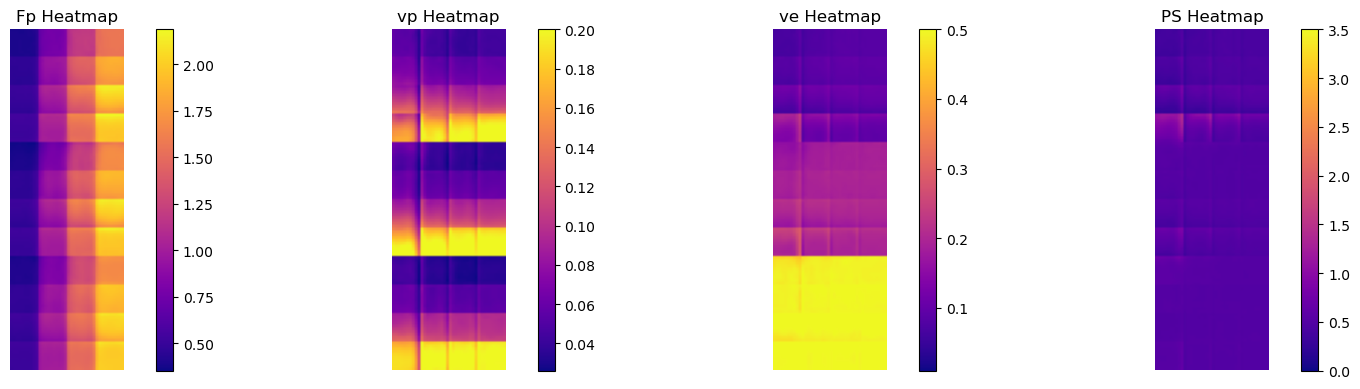

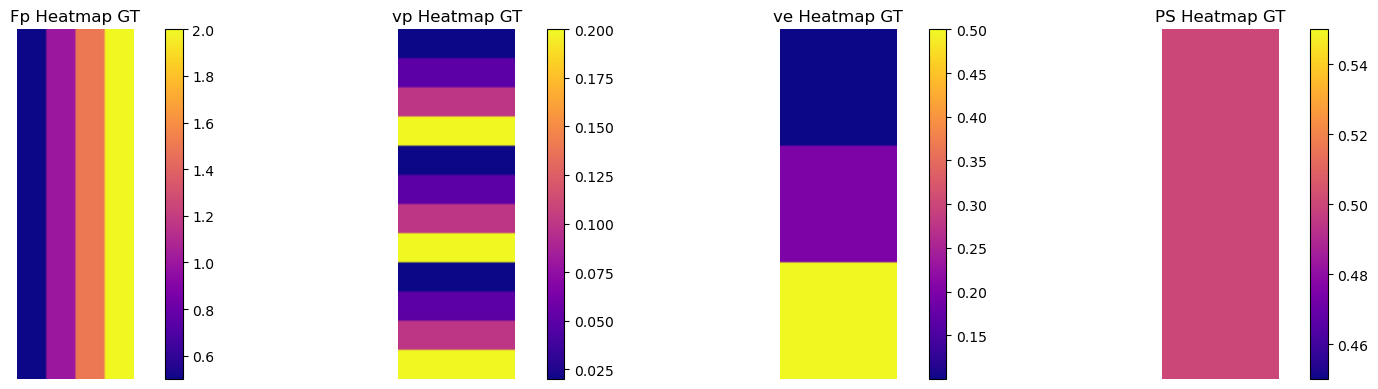

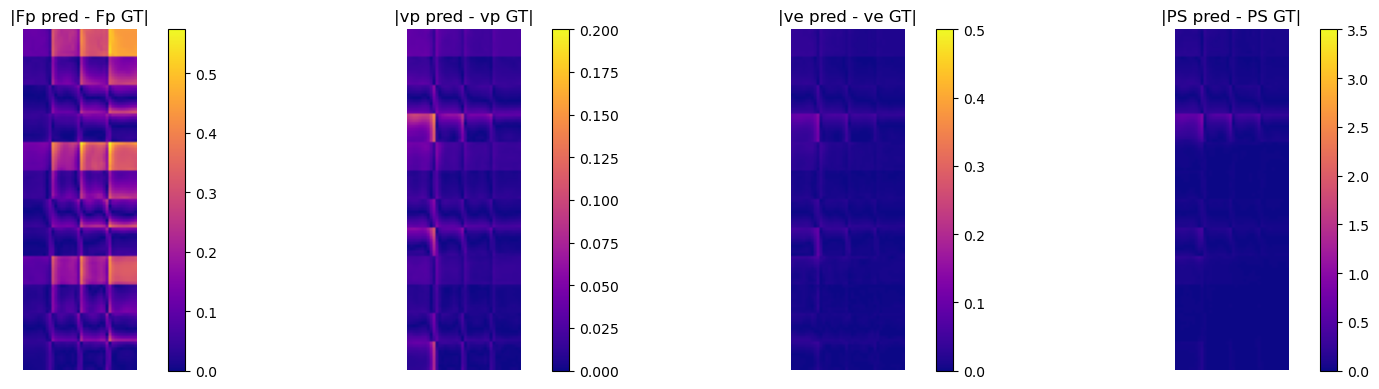

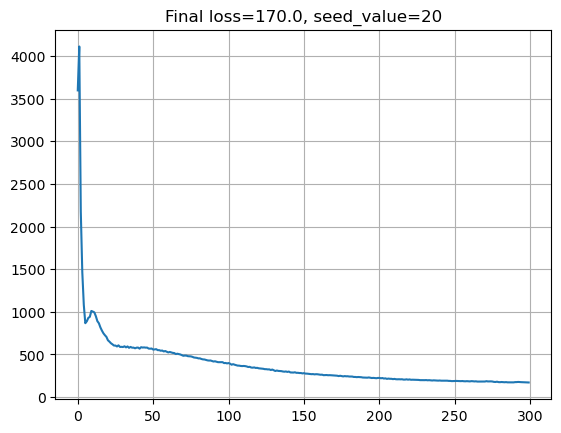

169.90848016738892


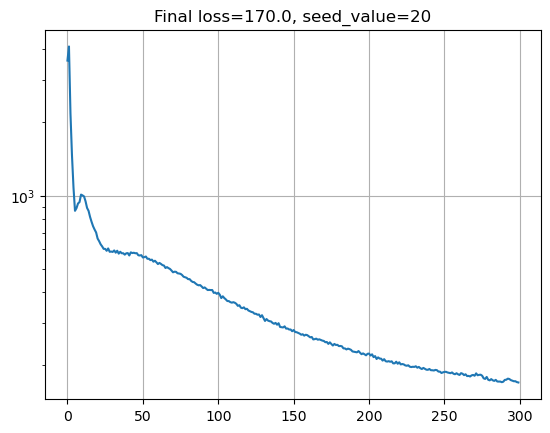

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:43<00:00,  1.34it/s]


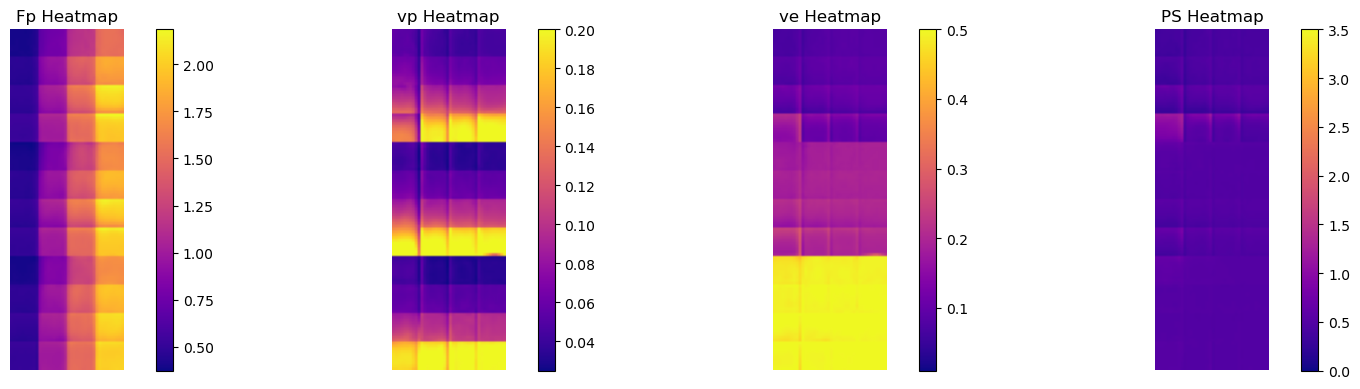

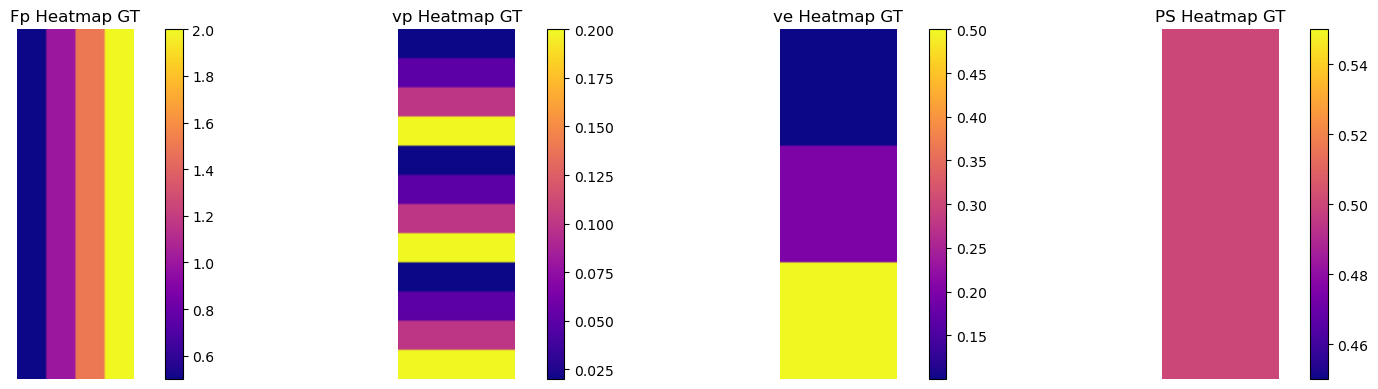

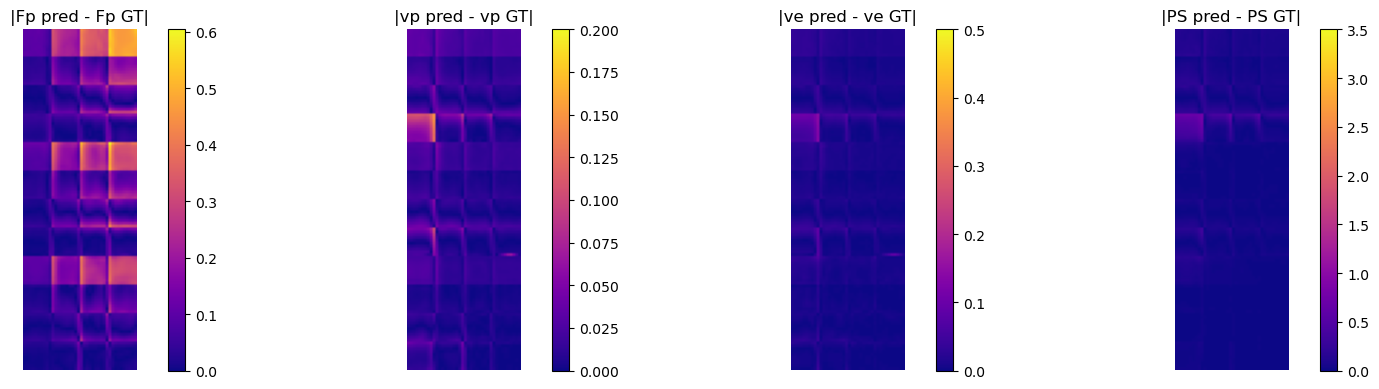

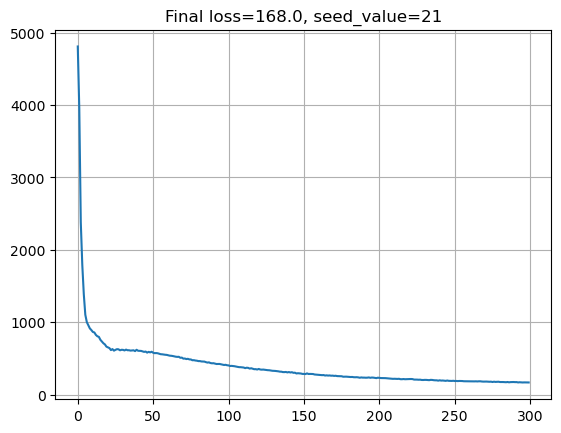

167.95547497272491


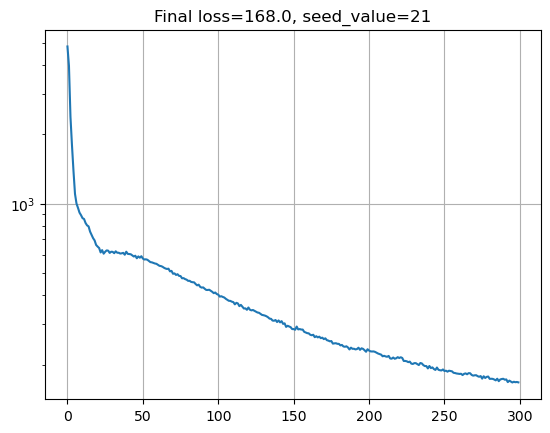

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:40<00:00,  1.36it/s]


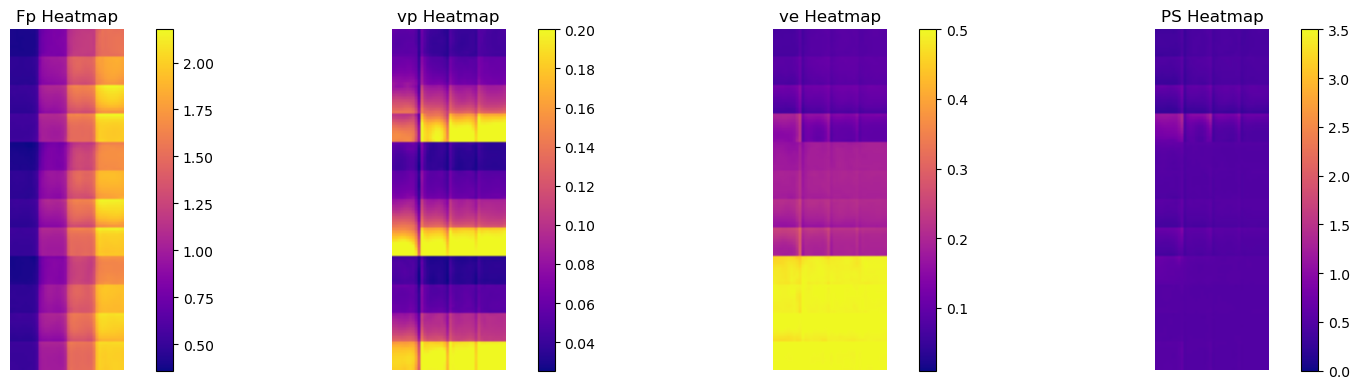

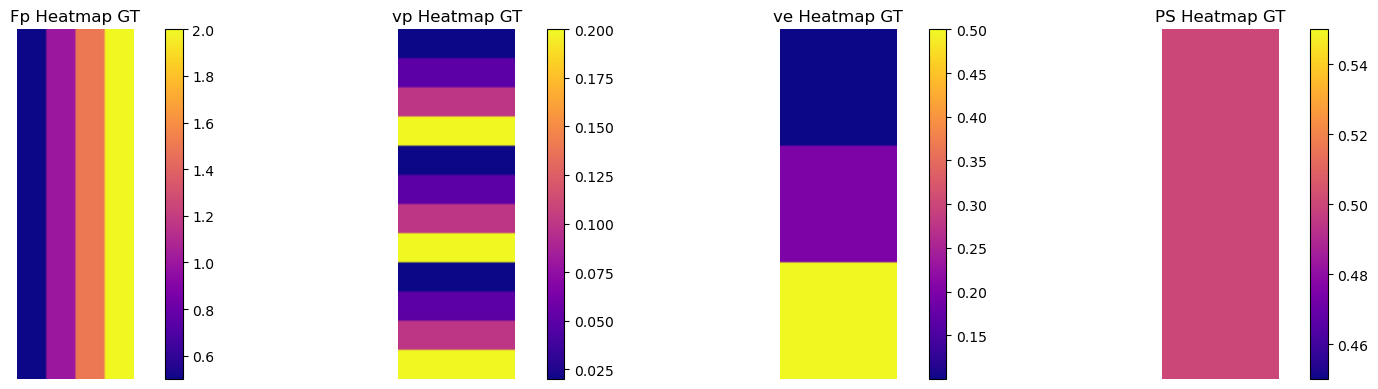

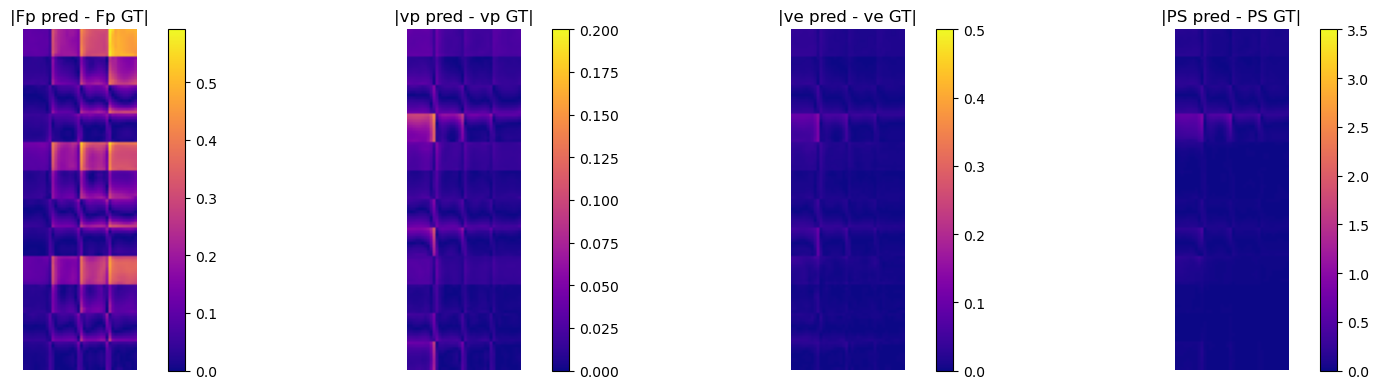

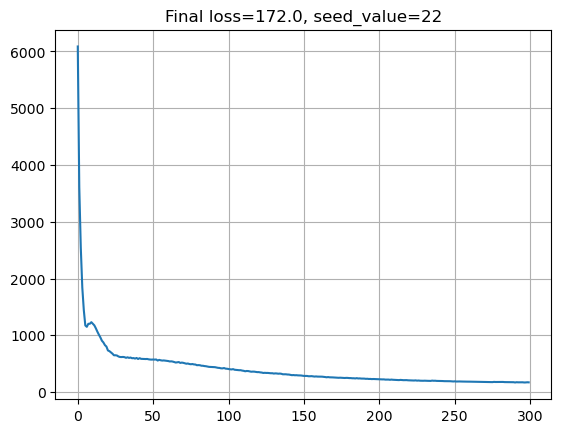

171.57336366176605


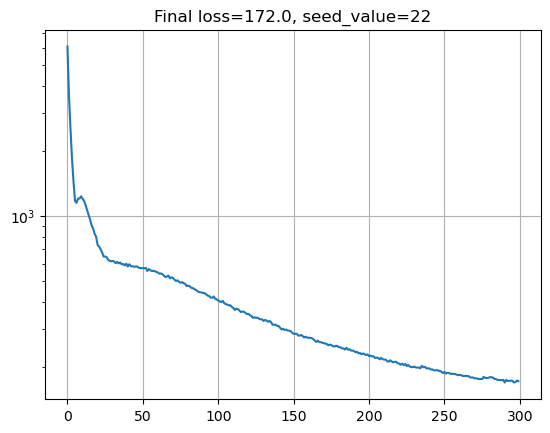

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:38<00:00,  1.37it/s]


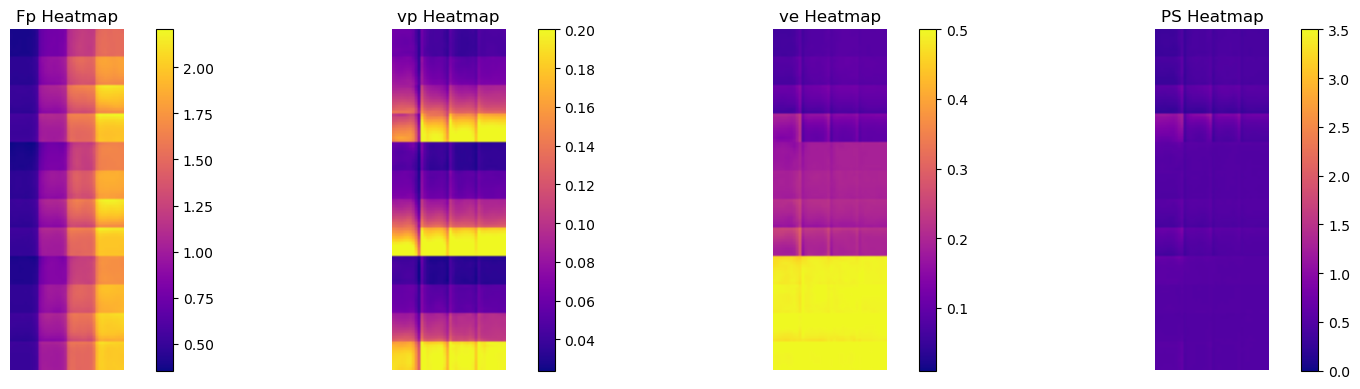

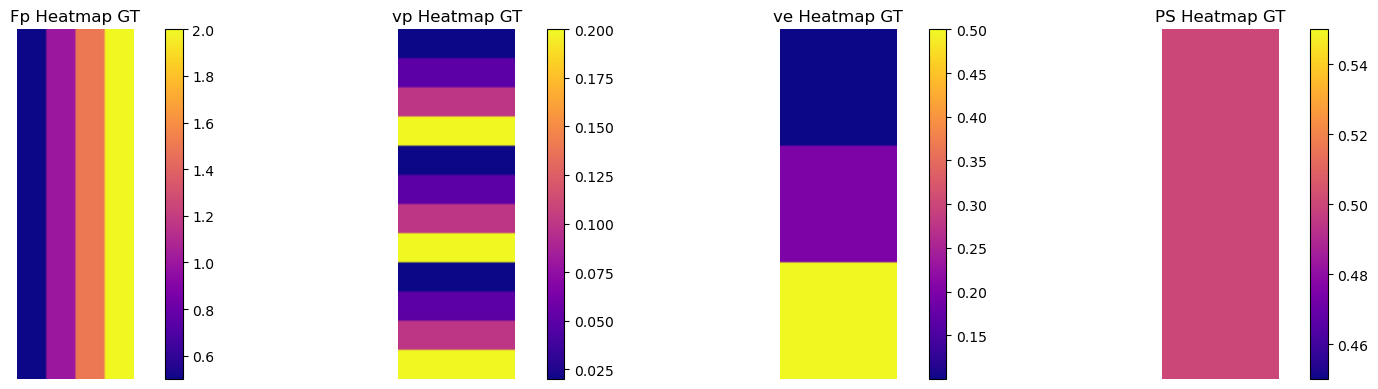

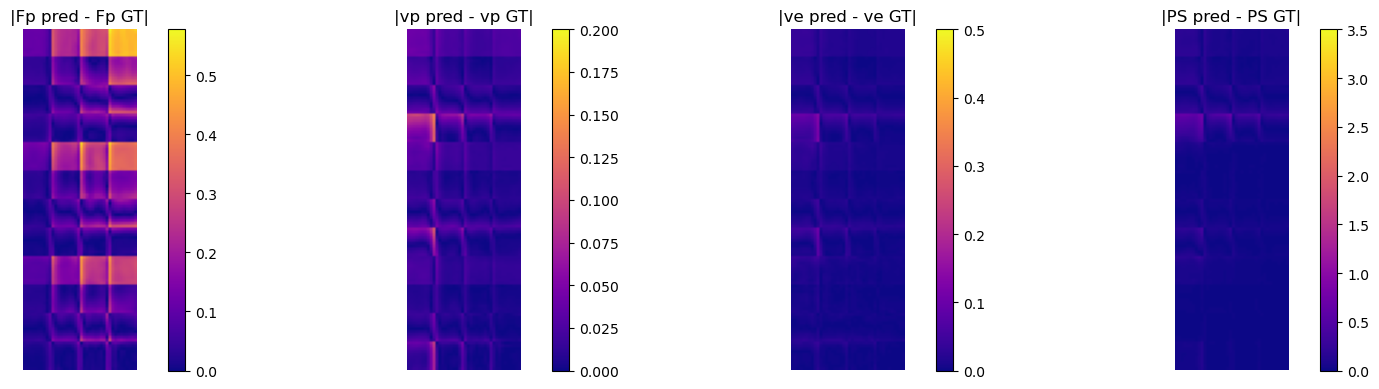

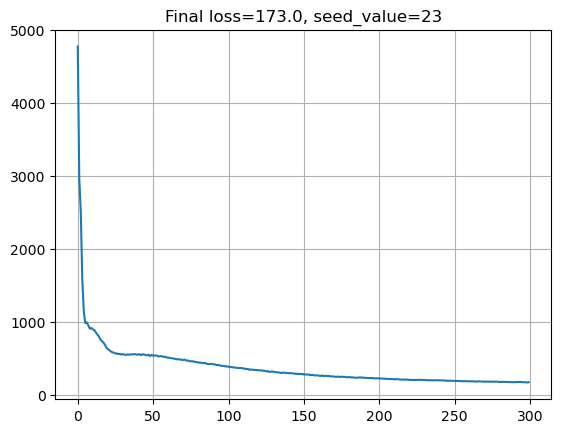

173.2843645811081


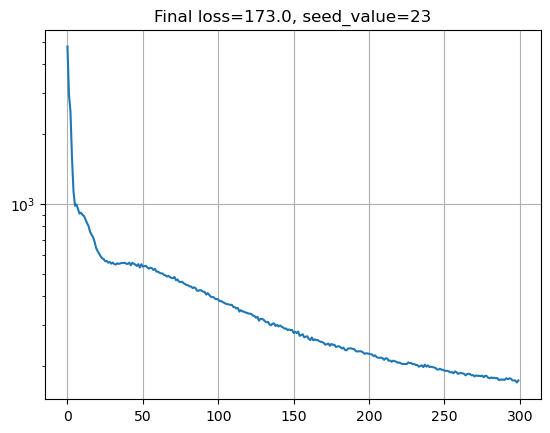

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:33<00:00,  1.40it/s]


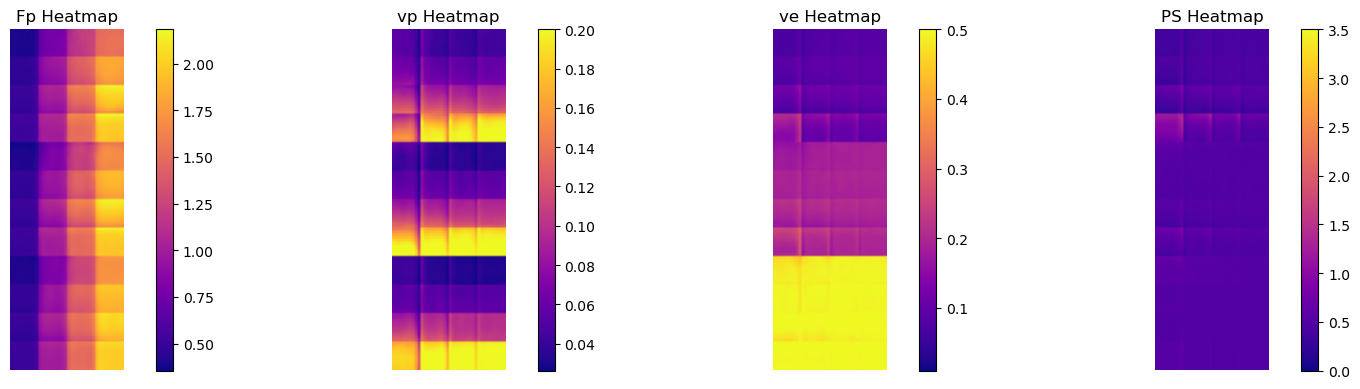

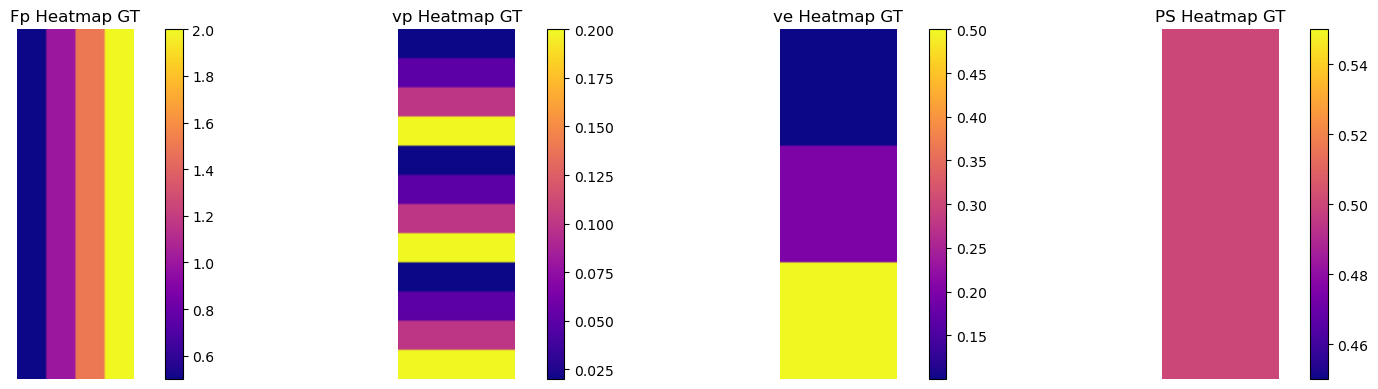

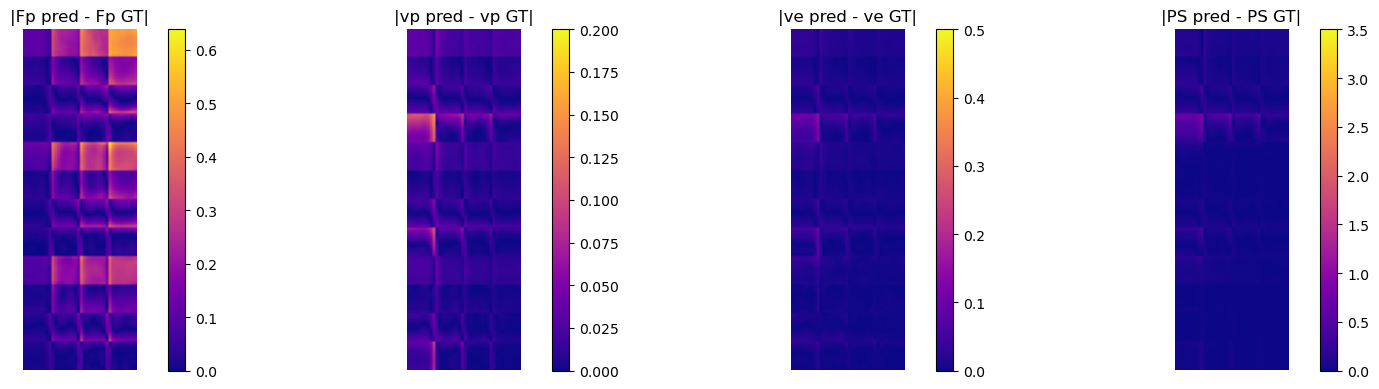

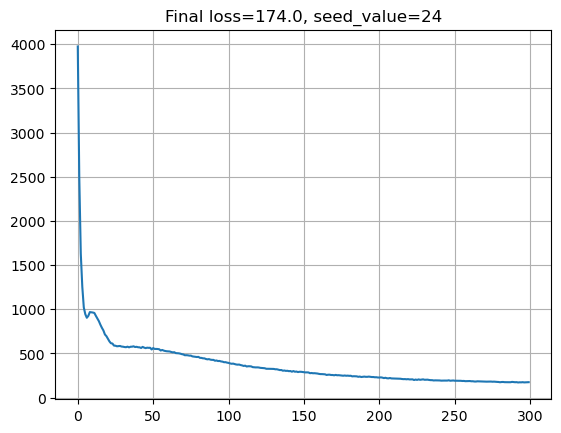

173.5709697008133


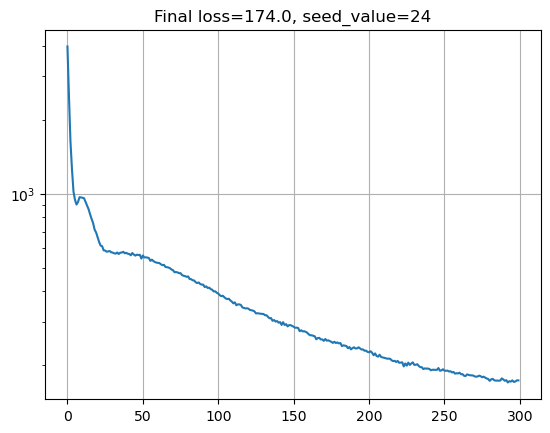

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:34<00:00,  1.40it/s]


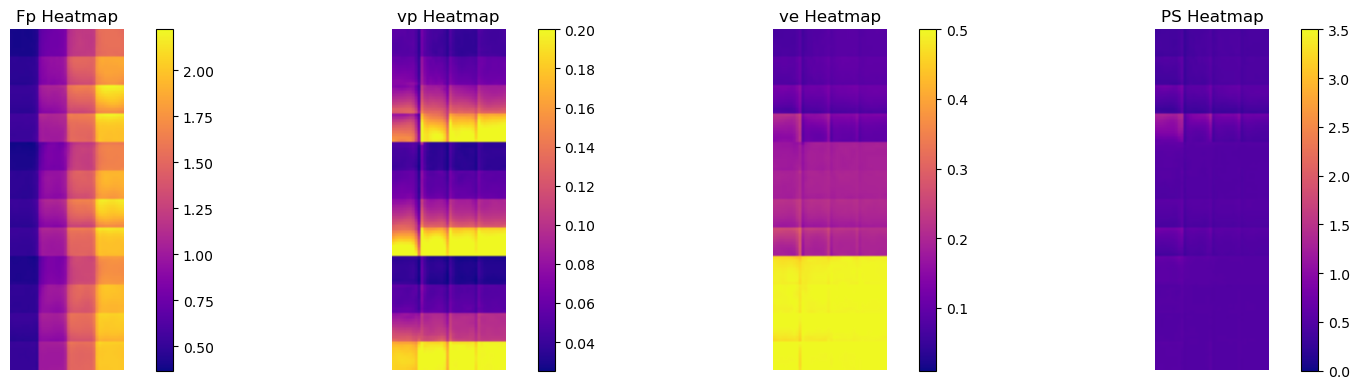

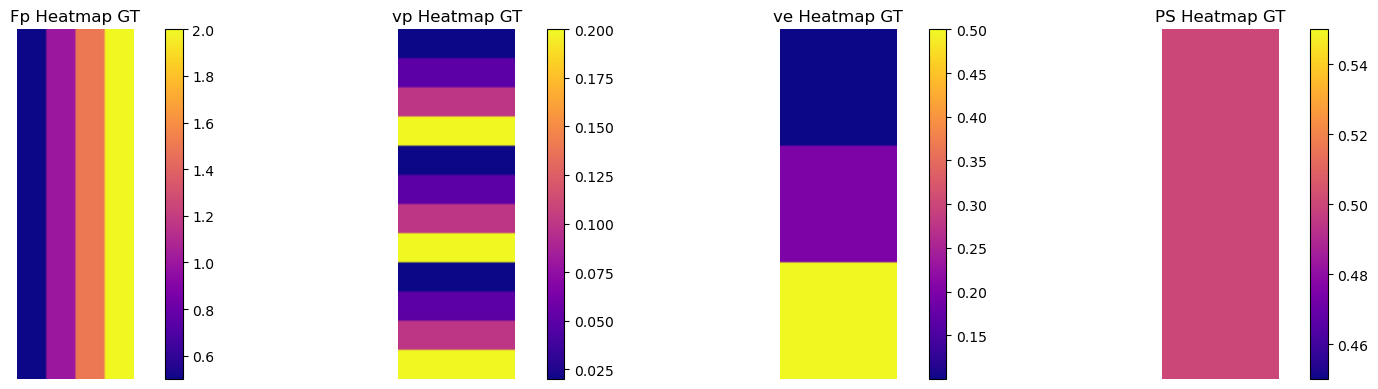

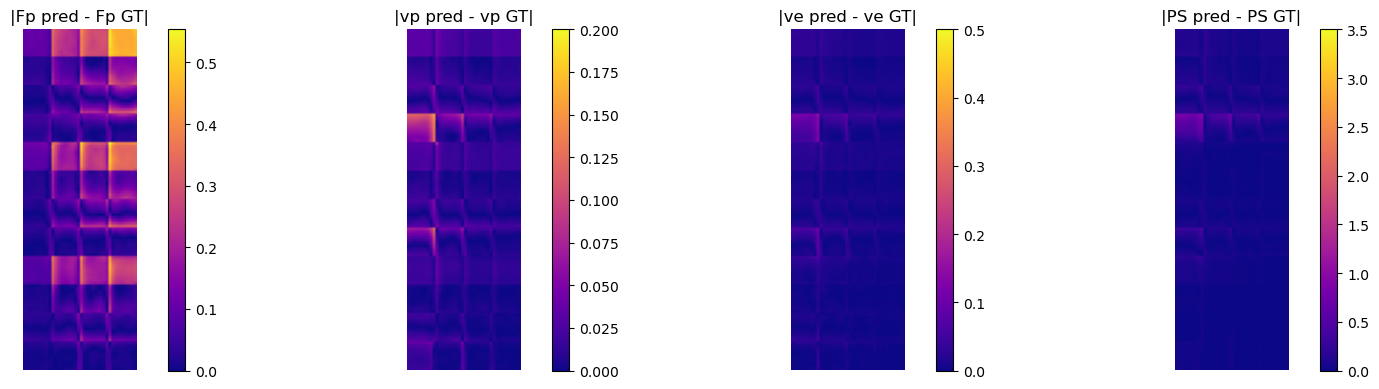

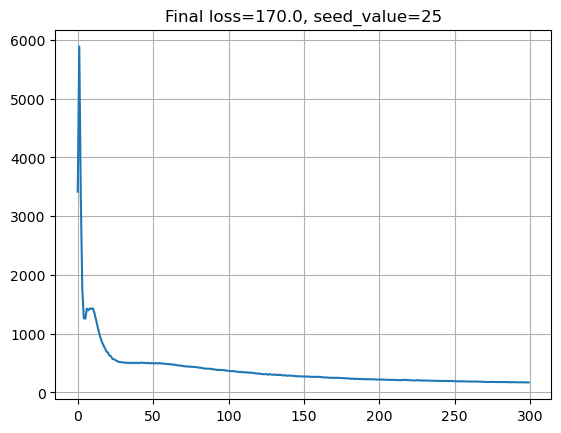

169.54525792598724


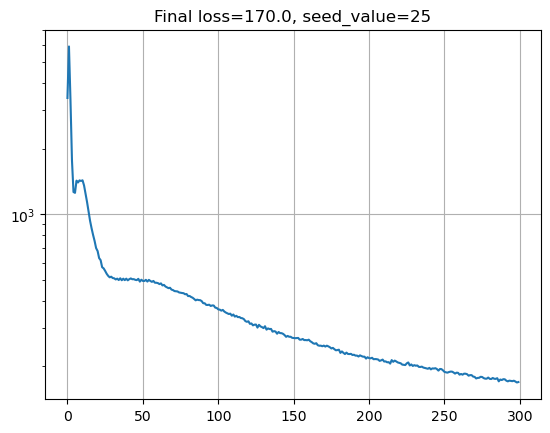

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:34<00:00,  1.40it/s]


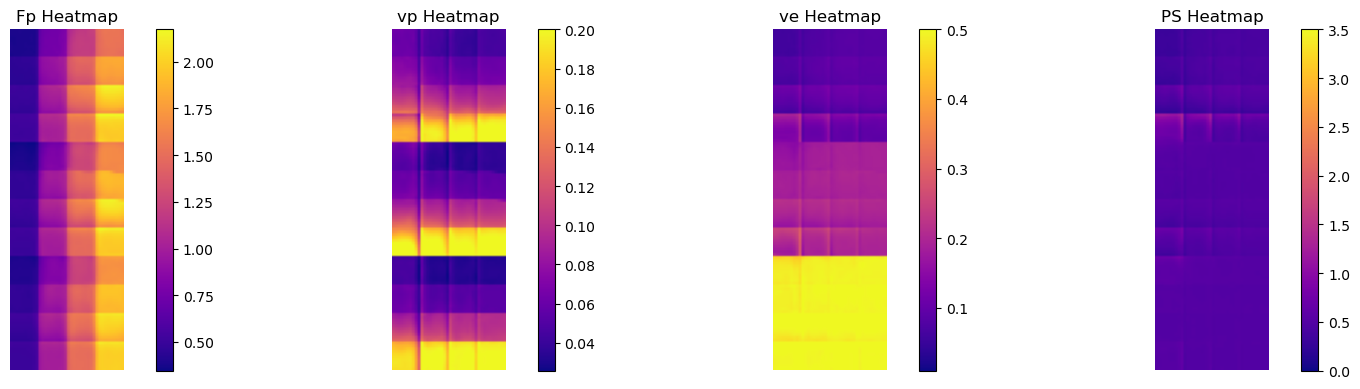

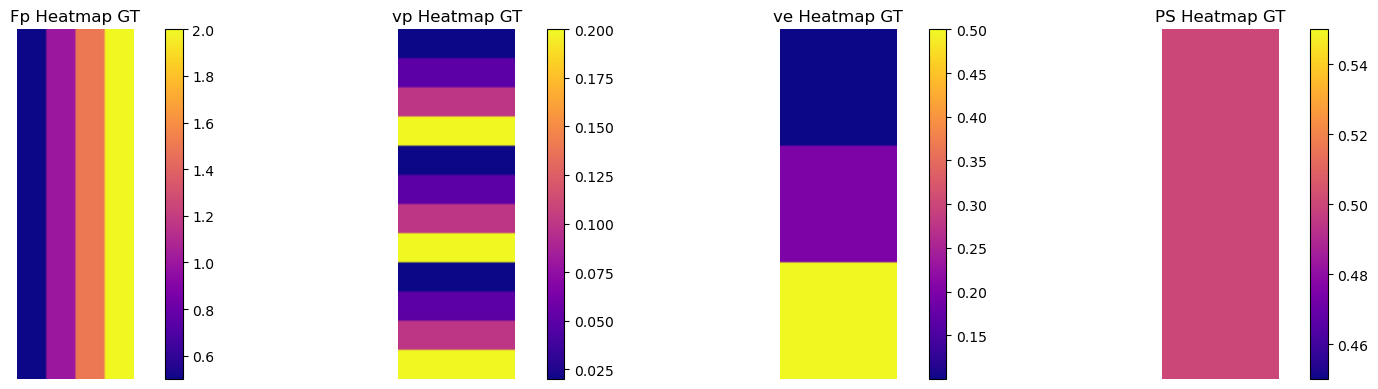

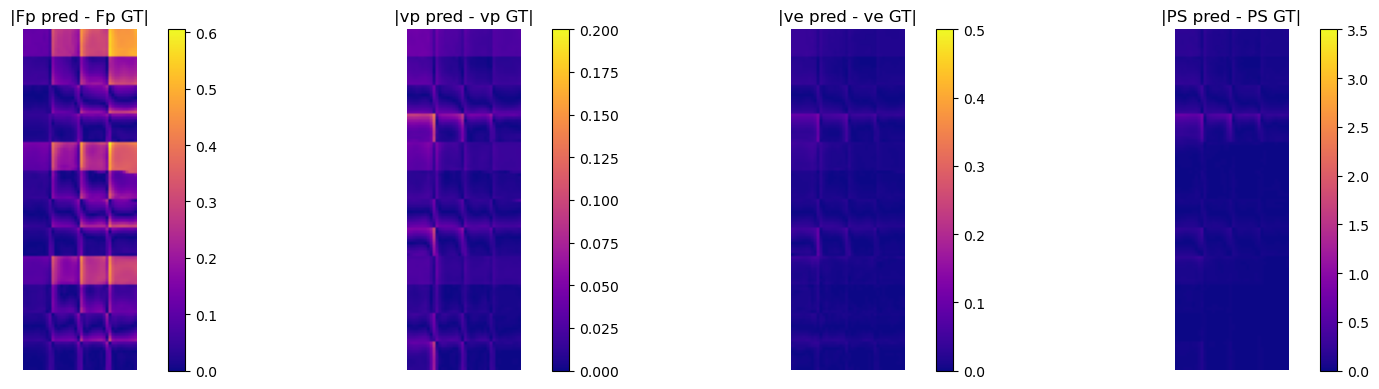

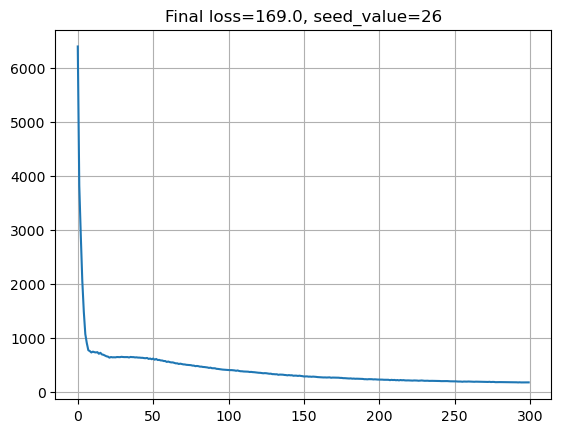

169.28582048416138


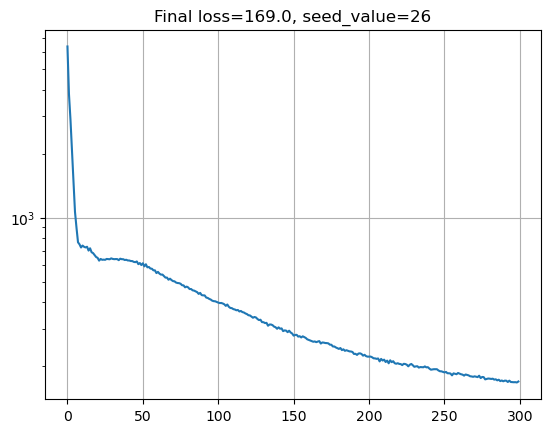

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:34<00:00,  1.40it/s]


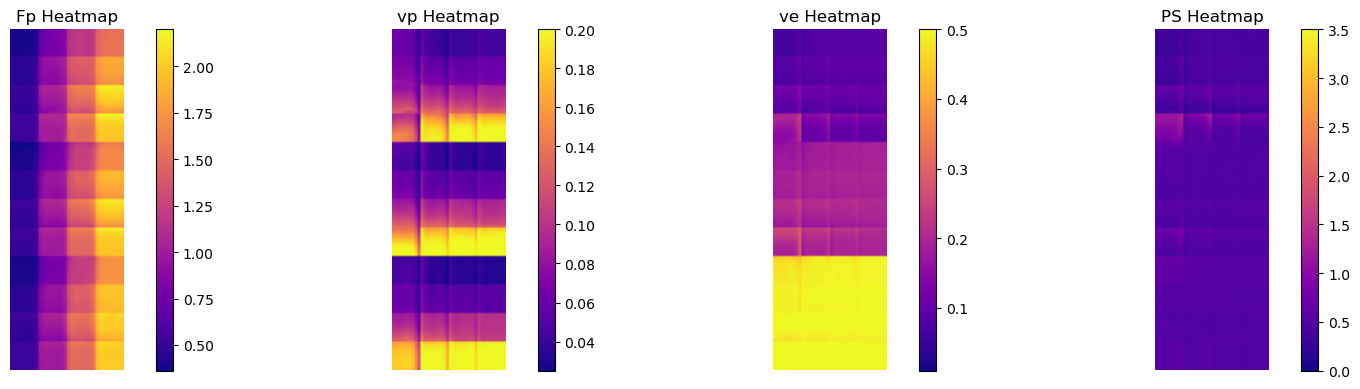

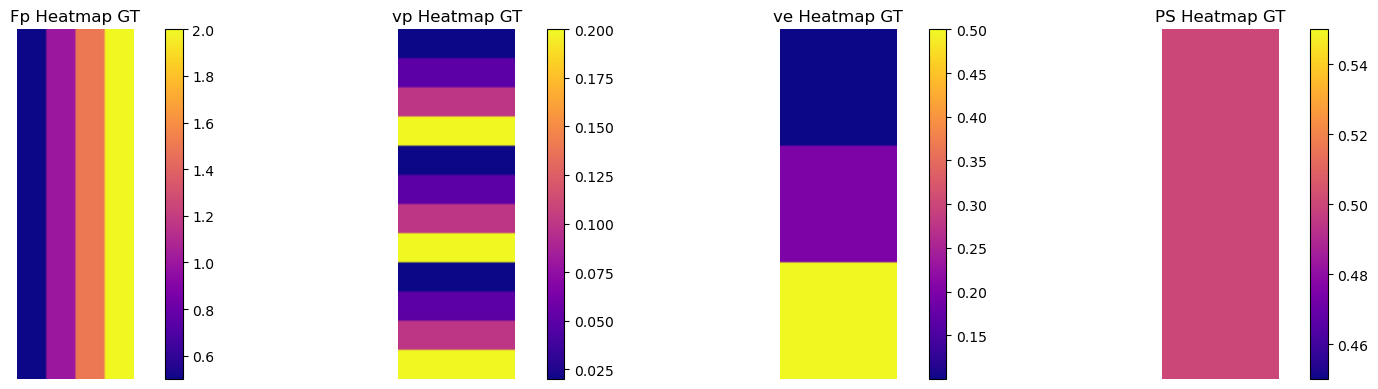

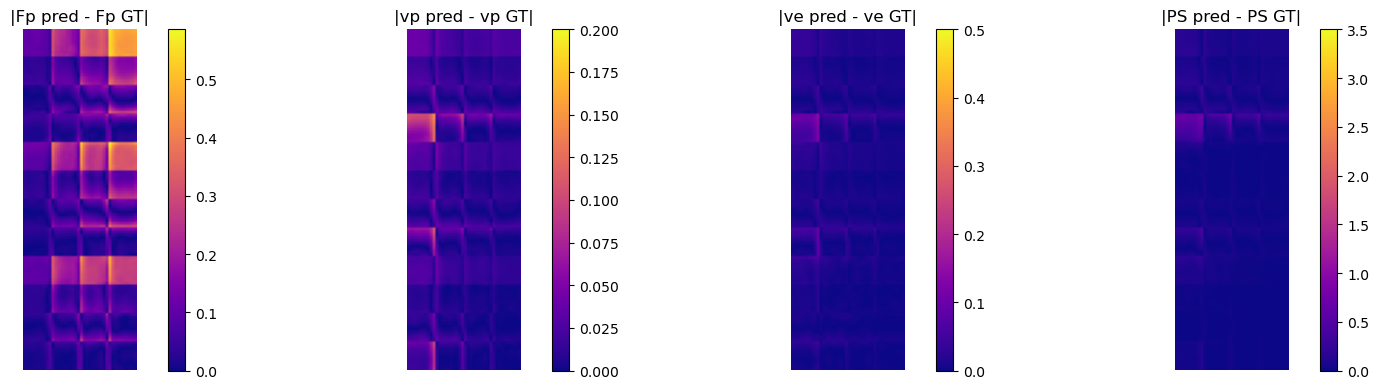

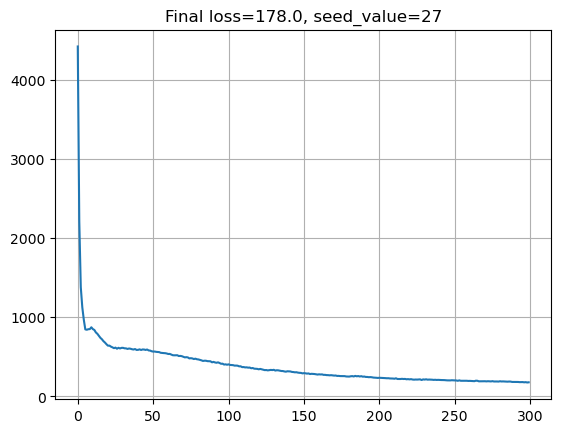

177.96918427944183


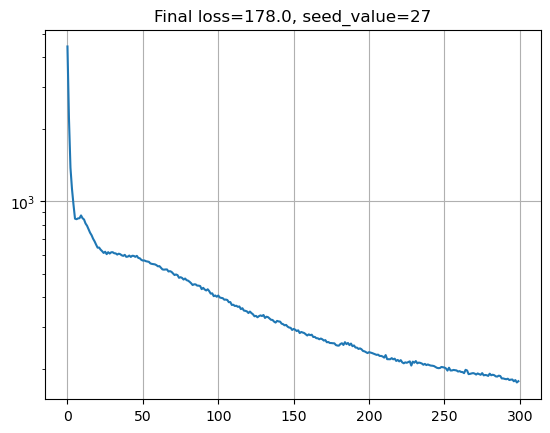

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [03:34<00:00,  1.40it/s]


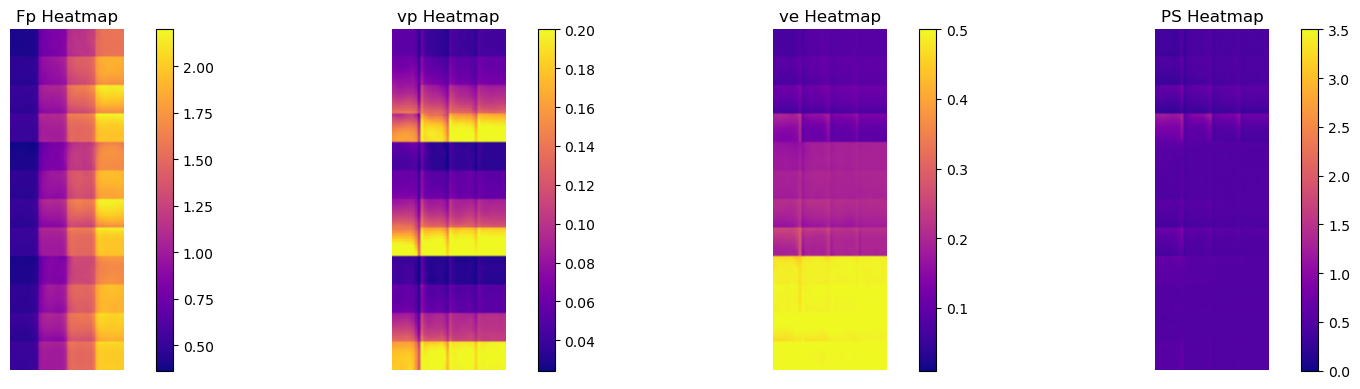

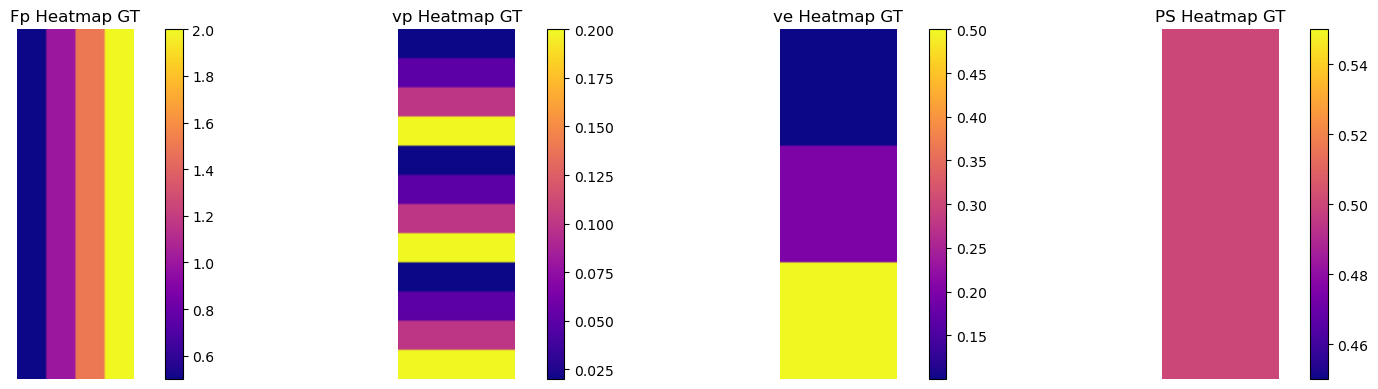

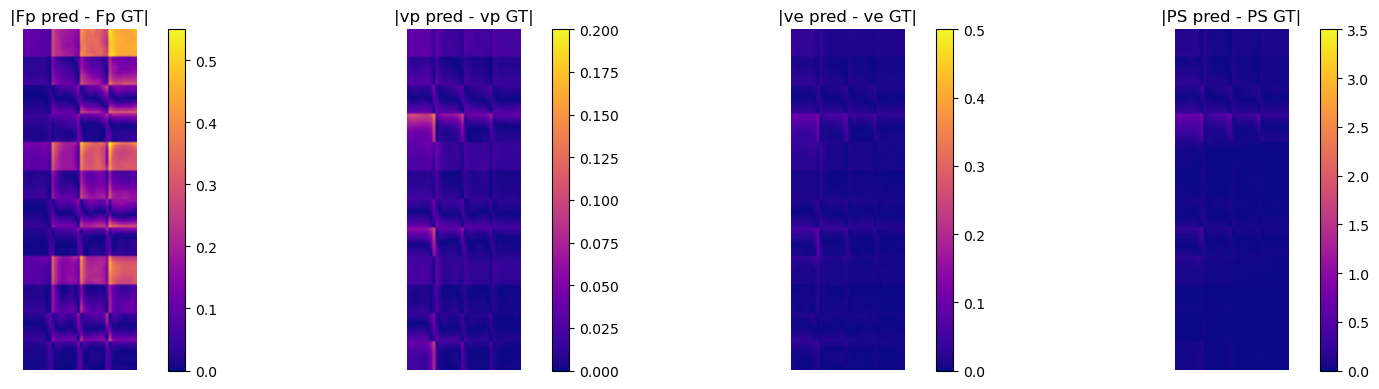

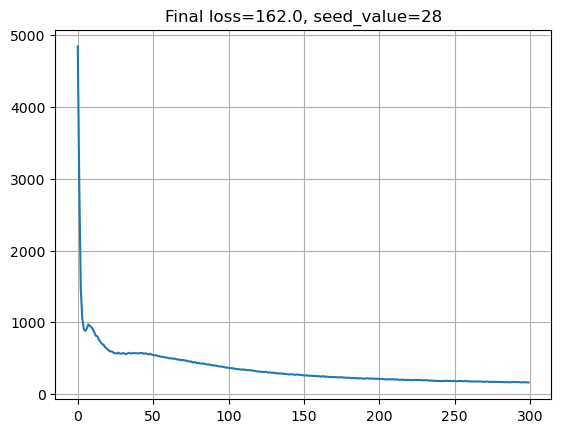

161.58393931388855


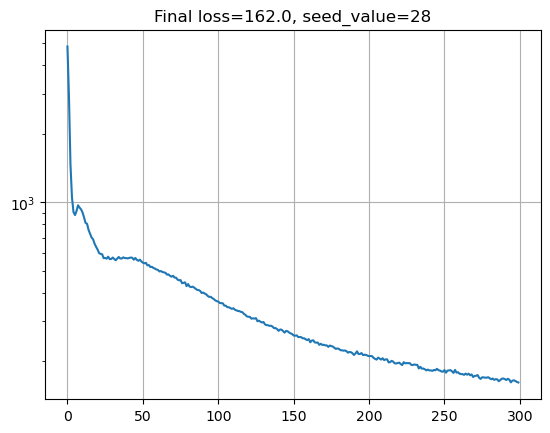

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)
Shape of aif_time, min, max: (100,), 0.0, 1.9800000190734863
Shape of t_norm, min, max: (100,), 0.0, 1.9800000190734863


100%|██████████| 300/300 [1:10:33<00:00, 14.11s/it]     


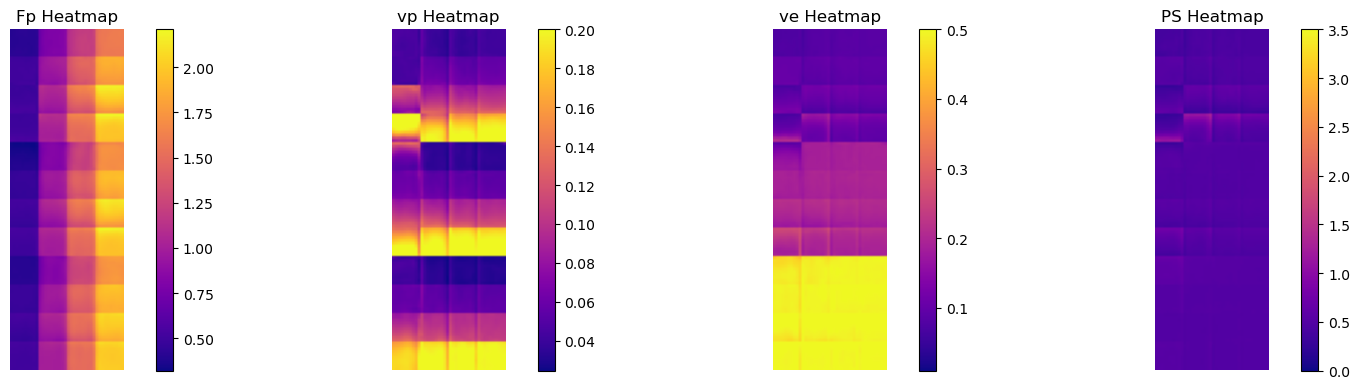

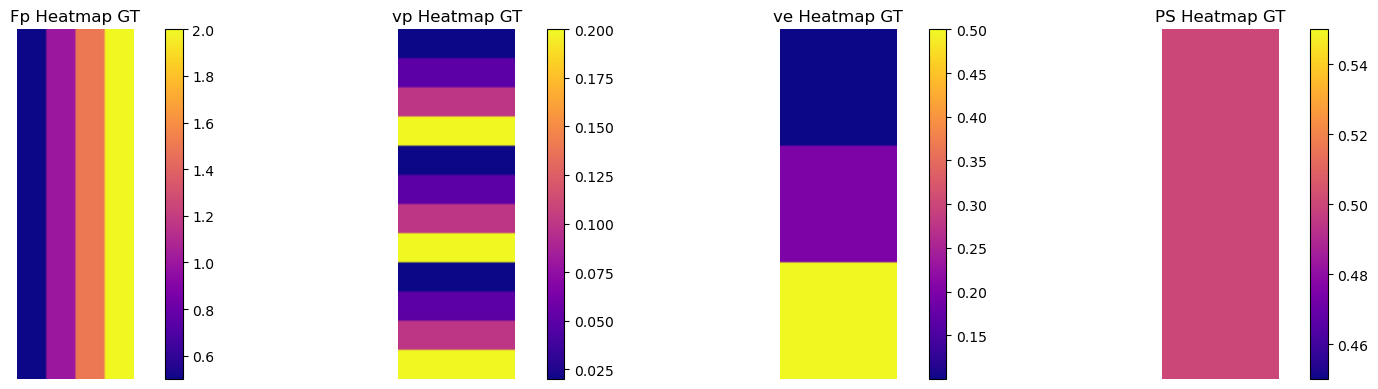

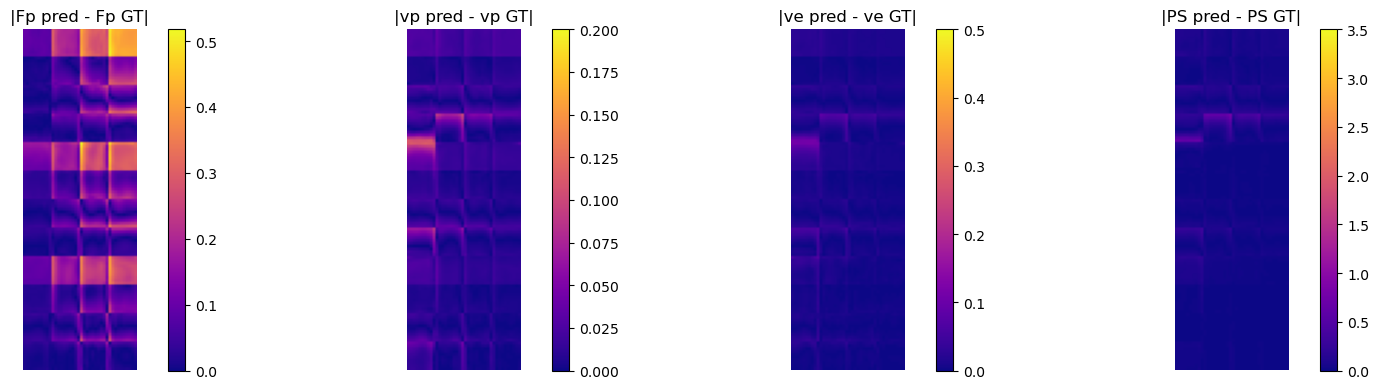

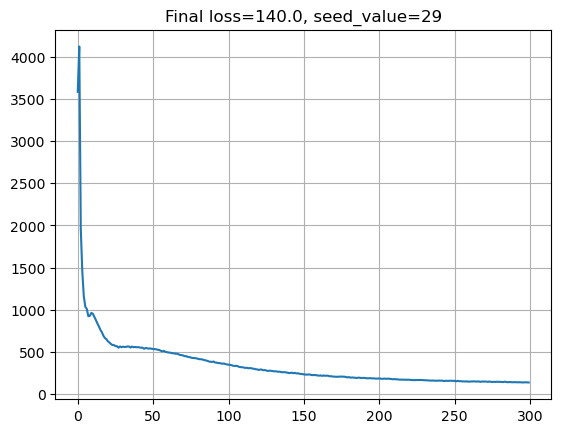

139.60174441337585


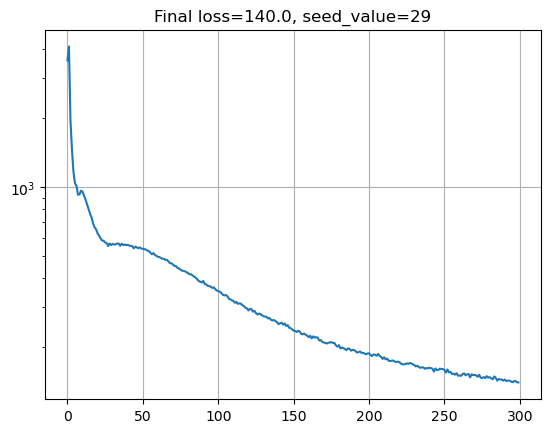

In [16]:
def main(seed_value, ps_slice, epochs, alpha):    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(tf_format=-1, ps_slice=ps_slice, snr=17.5) # type: ignore
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = train_pinn(myo_curves, myo_pars, aif_time, aif, 
            epochs=epochs, batch_size=512, seed_value=seed_value,
            num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
            num_layers_myo=5, dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
            num_layers_2cxm=5, dim_hidden_2cxm=512, w0_2cxm=10, w0_initial_2cxm=20,
            loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_2cxm=10.0,
            alpha = alpha
            #lr_adam_aif=3e-5 #was 1e-4
    ) #added two last losses
    
    # # save models
    # torch.save(model_aif.state_dict(), "model_aif.pth")
    # torch.save(model_myo.state_dict(), "model_myo.pth")
    # torch.save(model_ode.state_dict(), "model_ode.pth")
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list

ps_slice=0
epochs = 300
seed_value = 0
alpha = 3e-3

# # HUBER hyperparams
# delta_aif = 10.0 #optimal
# delta_myo = 0.01
# delta_ode = 0.01

# SOAP hyperparams
# lr_adam_aif = 1e-4
# lr_soap_p = 3e-5
# lr_soap_e = 1e-4
# lr_soap_ode= 2e-4

seed_values = np.arange(20,30)
final_loss = np.zeros(shape=(len(seed_values), 3)) # 3 : 300 epochs (30, 100, 300)
i = 0
for seed_value in seed_values:
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = main(seed_value, ps_slice, epochs, alpha)

    cost_sum = np.sum(np.array(cost_list), axis=1) # Fp+ve+vp+ps losses
    plt.plot(cost_sum)
    plt.grid()
    plt.title("Final loss={}, seed_value={}".format(np.around(cost_sum[-1], 0), seed_value))
    plt.show()
    print(cost_sum[-1])
    plt.plot(cost_sum)
    plt.grid()
    plt.title("Final loss={}, seed_value={}".format(np.around(cost_sum[-1], 0), seed_value))
    plt.yscale("log")
    plt.show()

    final_loss[i][0] = cost_sum[29]
    final_loss[i][1] = cost_sum[99]
    final_loss[i][2] = cost_sum[299]
    #final_loss[i][3] = cost_sum[999]
    #final_loss[i][4] = cost_sum[2999]

    i += 1

In [17]:
print(final_loss.T)

[[588.12635422 619.05921555 616.85852337 552.69314861 577.21920967
  516.44450855 643.20257378 613.51321316 563.64947987 557.43835831]
 [393.88600016 405.71869683 410.98680162 389.07710123 394.97814274
  371.14112854 401.04738188 400.36834669 367.97140098 352.69085646]
 [169.90848017 167.95547497 171.57336366 173.28436458 173.5709697
  169.54525793 169.28582048 177.96918428 161.58393931 139.60174441]]


## Here we do the evaluation of the hybrid model

In [22]:
def round_sig(x, n=3):
    return float(f"{x:.{n}g}")

<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
C:\Users\beren\AppData\Local\Temp\ipykernel_12420\1126274187.py:33: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(fl_30, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
C:\Users\beren\AppData\Local\Temp\ipykernel_12420\1126274187.py:34: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(fl_100, label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
C:\Users\beren\AppData\Local\Temp\ipykernel_12420\1126274187.py:35: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(fl_300, label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))


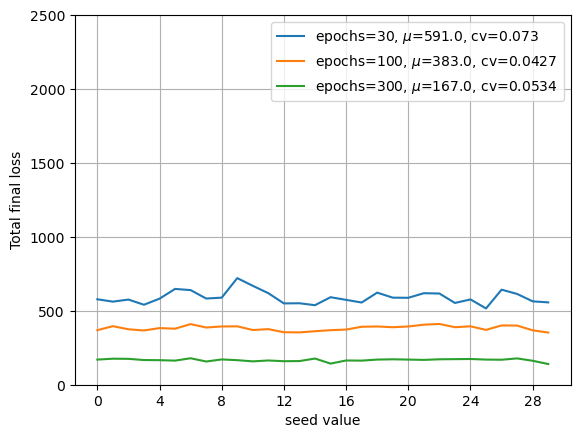

In [25]:
fl_09_30 = [578, 562, 576, 541, 582, 648, 640, 583, 589, 721]
fl_09_100 = [369, 396, 375, 367, 383, 379, 410, 387, 394, 395]
fl_09_300 = [170, 176, 175, 167, 166, 163, 179, 157, 171, 166]

fl_1019_30 = [669, 619, 550, 551, 538, 592, 574, 556, 623, 589]
fl_1019_100 = [370, 376, 355, 354, 362, 369, 373, 392, 394, 389]
fl_1019_300 = [158, 164, 159, 160, 177, 143, 164, 163, 170, 172]

fl_2029_30 = [588, 619, 617, 553, 577, 516, 643, 614, 564, 557]
fl_2029_100 = [394, 406, 411, 389, 395, 371, 401, 400, 368, 353]
fl_2029_300 = [170, 168, 172, 173, 174, 170, 169, 178, 162, 140]

fl_30 = []
for fl_list in [fl_09_30, fl_1019_30, fl_2029_30]:
    for elt in fl_list:
        fl_30.append(elt)
fl_100 = []
for fl_list in [fl_09_100, fl_1019_100, fl_2029_100]:
    for elt in fl_list:
        fl_100.append(elt)
fl_300 = []
for fl_list in [fl_09_300, fl_1019_300, fl_2029_300]:
    for elt in fl_list:
        fl_300.append(elt)

mu_30 = round_sig(np.mean(fl_30))
mu_100 = round_sig(np.mean(fl_100))
mu_300 = round_sig(np.mean(fl_300))
cv_30 =  round_sig( np.std(fl_30)/np.abs(np.mean(fl_30)) )
cv_100 = round_sig( np.std(fl_100)/np.abs(np.mean(fl_100)) )
cv_300 = round_sig( np.std(fl_300)/np.abs(np.mean(fl_300)) )

plt.plot(fl_30, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
plt.plot(fl_100, label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
plt.plot(fl_300, label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))
plt.grid()
plt.ylim(0,2500)
plt.ylabel("Total final loss")
plt.xlabel("seed value")
plt.xticks(np.arange(0,30,4))
plt.legend()

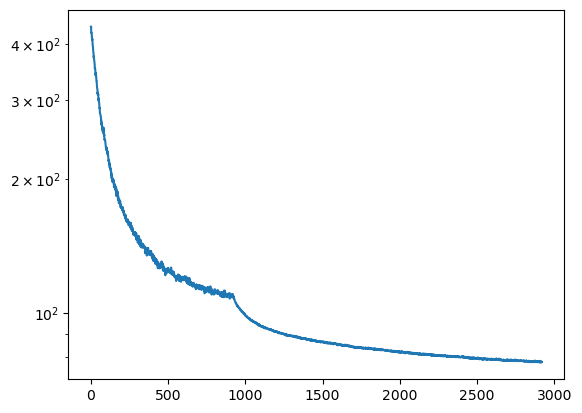

In [15]:
plt.plot(cost_sum[80:])
plt.yscale("log")

In [26]:
print(final_loss)
final_loss_full = list( final_loss )
final_loss_full[0].append(78)
print(final_loss_full)
alpha = [3e-3]
print(alpha)
print(final_loss_full.T) #1e-4

[[578.1558609  376.00958157 164.72358596 109.14412916]]


AttributeError: 'numpy.ndarray' object has no attribute 'append'

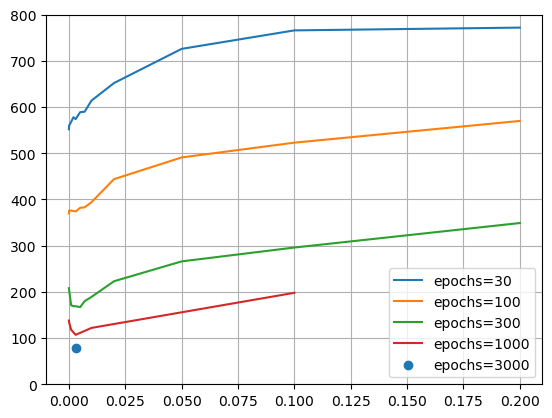

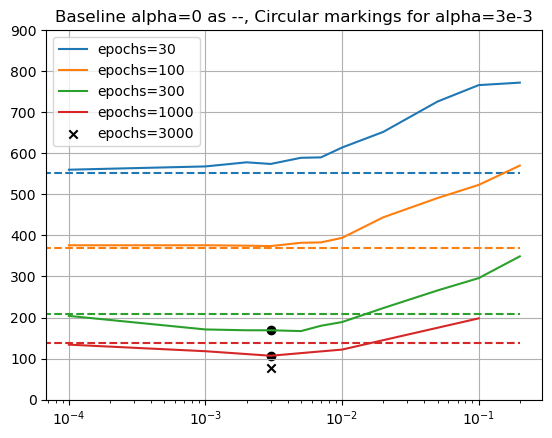

In [29]:
# DATA:  Without splitting of the optimizer and criterion
#fixed seed value = 0

fl_30 = [552, 560, 568, 578, 574, 589, 590, 614, 652, 726, 766, 772]
fl_100 = [370, 376, 376, 375, 374, 382, 383, 394, 444, 491, 523, 570]
fl_300 = [208, 204, 171, 169, 169, 167, 180, 189, 223, 266, 296, 349]
fl_1000 = [138, 134, 118, 107, 122, 198] #107
fl_3000 = [78]

alpha_values = [0, 1e-4, 0.001, 0.002, 0.003, 0.005, 0.007, 0.01, 0.02, 0.05, 0.1, 0.2]
alpha_values_1000 = [0, 1e-4, 1e-3, 3e-3, 1e-2, 0.1]
alpha_values_3000 = [3e-3]

plt.plot(alpha_values, fl_30, label="epochs=30")
plt.plot(alpha_values, fl_100, label="epochs=100")
plt.plot(alpha_values, fl_300, label="epochs=300")
plt.plot(alpha_values_1000, fl_1000, label="epochs=1000")
plt.scatter(alpha_values_3000, fl_3000, label="epochs=3000")
#plt.xscale("log")
plt.legend()
plt.ylim(0,800)
plt.grid()
plt.show()

c = plt.rcParams['axes.prop_cycle'].by_key()['color']

plt.plot(alpha_values[1:], fl_30[1:], label="epochs=30", color=c[0])
plt.plot([alpha_values[0], alpha_values[-1]], [fl_30[0], fl_30[0]], linestyle="--", color=c[0])

plt.plot(alpha_values[1:], fl_100[1:], label="epochs=100", color=c[1])
plt.plot([alpha_values[0], alpha_values[-1]], [fl_100[0], fl_100[0]], linestyle="--", color=c[1])

plt.plot(alpha_values[1:], fl_300[1:], label="epochs=300", color=c[2])
#plt.scatter(alpha_values[4], fl_300[4], label="alpha={}, epochs=300".format(alpha_values[4]), color="black")
plt.scatter(alpha_values[4], fl_300[4], color="black")
plt.plot([alpha_values[0], alpha_values[-1]], [fl_300[0], fl_300[0]], linestyle="--", color=c[2])

plt.plot(alpha_values_1000[1:], fl_1000[1:], label="epochs=1000", color=c[3])
#plt.scatter(alpha_values_1000[3], fl_1000[3], label="alpha={}, epochs=1000".format(alpha_values[4]), color="grey")
plt.scatter(alpha_values_1000[3], fl_1000[3], color="black")
plt.plot([alpha_values[0], alpha_values[-1]], [fl_1000[0], fl_1000[0]], linestyle="--", color=c[3])

plt.scatter(alpha_values_3000[0], fl_3000[0], color="black", marker="x", label="epochs=3000")

plt.xscale("log")
plt.legend()
plt.ylim(0,900)
plt.grid()
plt.title("Baseline alpha=0 as --, Circular markings for alpha=3e-3")
plt.show()

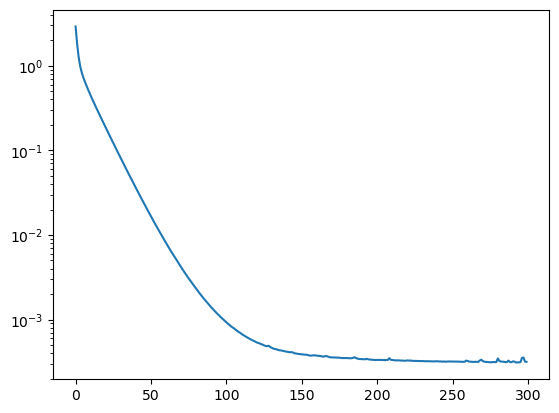

In [39]:
plt.plot(total_losses)
plt.yscale("log")

[[507.73299503 381.72416139 206.93306422]
 [617.09708548 381.12336254 202.89592385]
 [600.24923754 406.32324314 214.05534148]
 [548.36853409 359.59246778 199.30822754]
 [545.80796814 354.1085906  161.72418082]]


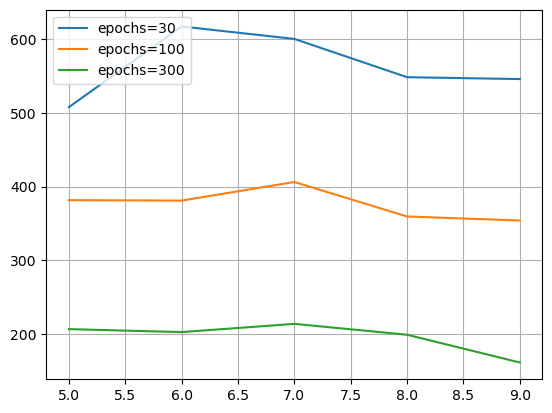

[[508. 617. 600. 548. 546.]
 [382. 381. 406. 360. 354.]
 [207. 203. 214. 199. 162.]]


In [28]:
print(final_loss)

seed_values = np.arange(5, 10)
labels = ["epochs=30", "epochs=100", "epochs=300"]
i = 0
for elt in final_loss.T:
    plt.plot(seed_values, elt, label=labels[i])
    i+= 1
plt.grid()
plt.legend()
plt.show()

print(np.around(final_loss.T))

In [33]:
def round_sig(x, n=3):
    return float(f"{x:.{n}g}")

<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
C:\Users\beren\AppData\Local\Temp\ipykernel_1696\2137389585.py:21: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, elt, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
C:\Users\beren\AppData\Local\Temp\ipykernel_1696\2137389585.py:28: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_30, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
C:\Users\beren\AppData\Local\Temp\ipykernel_1696\2137389585.py:29: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_100, label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv

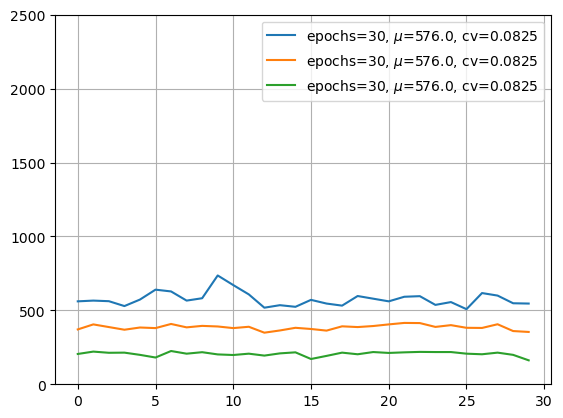

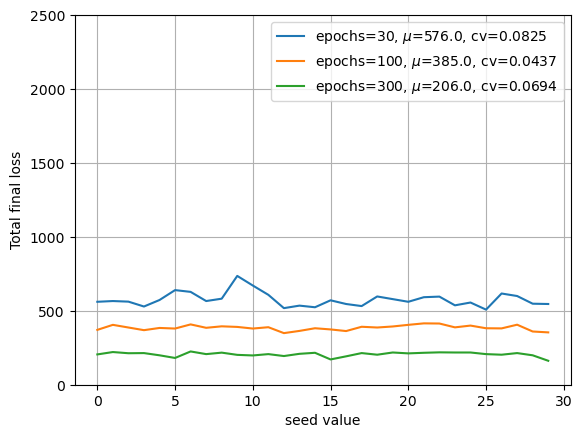

In [37]:
# DATA: 3A data, meaning convolutional loss, Huber criterion and SOAP optimizer

fl_30 = [561, 566, 562, 529, 573, 640, 628, 566, 582, 736, 671, 608, 518, 535, 524\
        ,571, 546, 532, 597, 579, 561, 592, 596, 537, 556, 508, 617, 600, 548, 546 ]
fl_100 = [371, 405, 387, 369, 384, 380, 408, 385, 395, 391, 380, 389, 349, 364, 382\
        ,374, 363, 392, 387, 394, 405, 415, 414, 388, 400, 382, 381, 406, 360, 354  ]
fl_300 = [205, 221, 213, 214, 199, 181, 225, 207, 217, 202, 198, 207, 194, 209, 216\
        , 171, 192, 214, 203, 218, 212, 216, 219, 218, 218, 207, 203, 214, 199, 162  ]

mu_30 = round_sig(np.mean(fl_30))
mu_100 = round_sig(np.mean(fl_100))
mu_300 = round_sig(np.mean(fl_300))
cv_30 =  round_sig( np.std(fl_30)/np.abs(np.mean(fl_30)) )
cv_100 = round_sig( np.std(fl_100)/np.abs(np.mean(fl_100)) )
cv_300 = round_sig( np.std(fl_300)/np.abs(np.mean(fl_300)) )

seed_values = np.arange(0, 30)
labels = ["epochs=30", "epochs=100", "epochs=300"]
i = 0
for elt in [fl_30, fl_100, fl_300]:
    plt.plot(seed_values, elt, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
    i+= 1
plt.legend()
plt.grid()
plt.ylim(0,2500)
plt.show()

plt.plot(seed_values, fl_30, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
plt.plot(seed_values, fl_100, label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
plt.plot(seed_values, fl_300, label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))
plt.legend()
plt.grid()
plt.ylim(0,2500)
plt.xlabel("seed value")
plt.ylabel("Total final loss")
plt.show()

# end

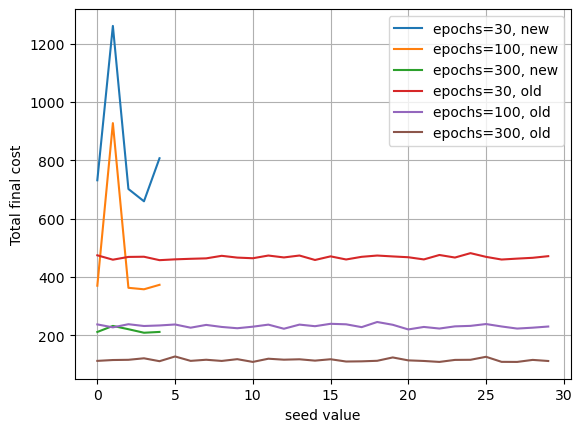

In [ ]:
# cell: redundant, because fl_comp is determined to be for fixed seed_value=4 aot swept seed value

# NEW DATA v1: lr_adam_aif=1e-4 

fl_new_30 = [751.99705696, 748.4434185, 741.16621208, 749.33919907, 742.19823456]
fl_new_100 = [382.68249226, 385.40552902, 391.20979261, 384.79871631, 385.03193617]
fl_new_300 = [203.61801028, 195.6419251, 199.84347653, 201.42990208, 197.86943436]

# NEW DATA v2: lr_adam_aif=3e-5

fl_new_30_b = [731.43896866, 1261.09616852, 701.51089048, 659.31462288, 807.04196835]
fl_new_100_b = [369.62840271, 927.56750965, 362.45938301, 357.36628819, 372.69022369]
fl_new_300_b = [210.9071219, 231.66991973, 220.35514116, 208.25823283, 211.06012559]

# OLD DATA: convolutional loss, with SOAP optimizer and Huber criterion

fl_comp_30 = [
    473.96046352, 458.92708874, 468.44218636, 469.06629944, 457.31005669,
    460.11284637, 462.00883865, 463.49053383, 472.2252636, 466.11706924,
    463.9006176, 473.1791153, 466.66944981, 473.22160721, 457.95514679,
    470.37953854, 459.65995216, 468.80749798, 473.16634941, 470.11709213,
    467.34605408, 459.82872486, 475.06389809, 466.31762505, 481.37908363,
    468.64978218, 459.47083855, 462.63180733, 465.43505383, 471.01636219
]

fl_comp_100 = [
    236.86152315, 226.72084141, 237.51689291, 231.39285421, 233.27364397,
    236.59006977, 225.6010747, 235.14878178, 228.15223503, 223.71281624,
    229.04288769, 236.09449244, 221.99657202, 236.18622398, 230.71145296,
    238.9437089, 237.19115734, 227.48637962, 245.12497568, 235.58380985,
    219.61418676, 228.14832401, 222.66392183, 230.1492815, 231.83804226,
    238.10144997, 229.7623682, 222.58214283, 225.63773298, 229.58117342
]

fl_comp_300 = [
    111.72916818, 114.64612579, 115.40181994, 120.58311009, 110.6156137,
    126.83989716, 111.75531268, 115.5757947, 111.53527784, 117.5719707,
    108.18461061, 119.12784481, 115.80710578, 117.17628384, 112.56507659,
    117.30925155, 109.50784111, 110.14778185, 111.99978495, 123.49525857,
    113.44472098, 111.41331244, 108.14892507, 115.03915381, 115.45029116,
    125.72468185, 108.38640189, 108.13283706, 115.07443953, 111.32601118
]



seed_values = np.arange(0, 5)
list_set_new = [fl_new_30_b, fl_new_100_b, fl_new_300_b]
label_list = ["epochs=30, new", "epochs=100, new", "epochs=300, new"]
i = 0
for list in list_set_new:
    plt.plot(seed_values, list, label=label_list[i])
    i+=1

seed_values = np.arange(0,30)
list_set = [fl_comp_30, fl_comp_100, fl_comp_300]
label_list = ["epochs=30, old", "epochs=100, old", "epochs=300, old"]
i = 0
for list in list_set:
    plt.plot(seed_values, list, label=label_list[i])
    i+=1


#plt.ylim(0,3000)
plt.xlabel("seed value")
plt.ylabel("Total final cost")
plt.grid()
plt.legend()
plt.show()

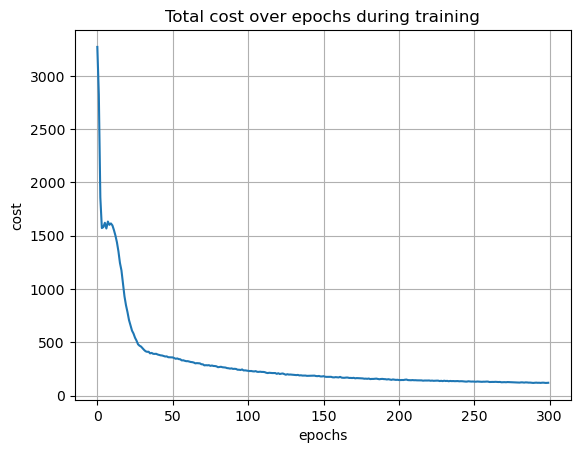

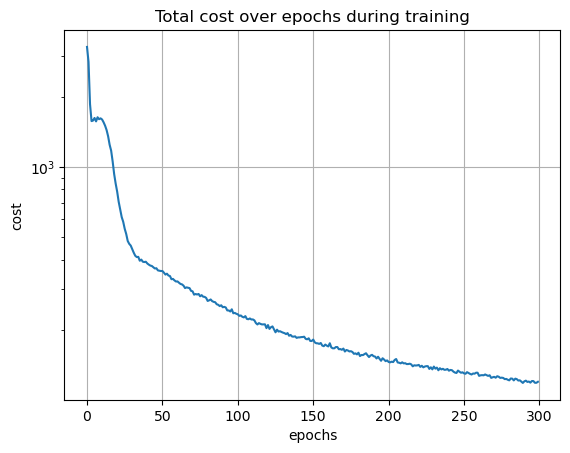

119.59750413894653


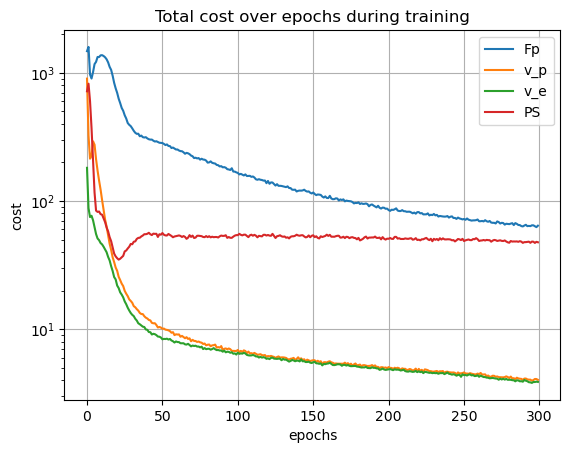

In [8]:
#0: cost over time

cost_sum = np.sum(np.array(cost_list), axis=1)
plt.plot(cost_sum)
plt.grid()
plt.title("Total cost over epochs during training")
plt.xlabel("epochs")
plt.ylabel("cost")
plt.show()

cost_sum = np.sum(np.array(cost_list), axis=1)
plt.plot(cost_sum)
plt.grid()
plt.title("Total cost over epochs during training")
plt.xlabel("epochs")
plt.ylabel("cost")
plt.yscale("log")
plt.show()

print(cost_sum[-1])

labels = ["Fp", "v_p", "v_e", "PS"]
for i in np.arange(0,4):
    label=labels[i]
    cost_elt = cost_list.T[i]
    plt.plot(cost_elt, label=label)
plt.grid()
plt.title("Total cost over epochs during training")
plt.xlabel("epochs")
plt.ylabel("cost")
plt.yscale("log")
plt.legend()
plt.show()

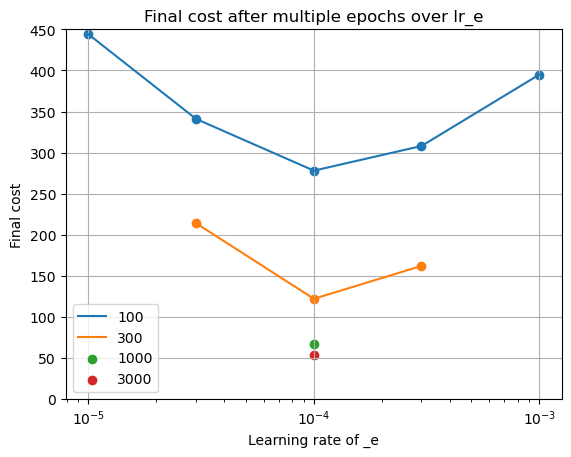

In [74]:
# 1: e sweep

lr_e_list_100 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3]
fl_list_100 = [444, 341, 278, 308, 395]
plt.plot(lr_e_list_100, fl_list_100, label=100)
plt.scatter(lr_e_list_100, fl_list_100)
lr_e_list_300 = [3e-5, 1e-4, 3e-4]
fl_list_300 = [214, 122, 162]
plt.plot(lr_e_list_300, fl_list_300, label=300)
plt.scatter(lr_e_list_300, fl_list_300)
lr_e_point_1000 = 1e-4
fl_point_1000 = 67
plt.scatter(lr_e_point_1000, fl_point_1000, label=1000)
lr_e_point_3000 = 1e-4
fl_point_3000 = 54
plt.scatter(lr_e_point_3000, fl_point_3000, label=3000)

plt.xscale("log")
plt.grid()
plt.title("Final cost after multiple epochs over lr_e")
plt.ylabel("Final cost")
plt.xlabel("Learning rate of _e")
plt.legend()
plt.ylim(0, 450)
plt.show()

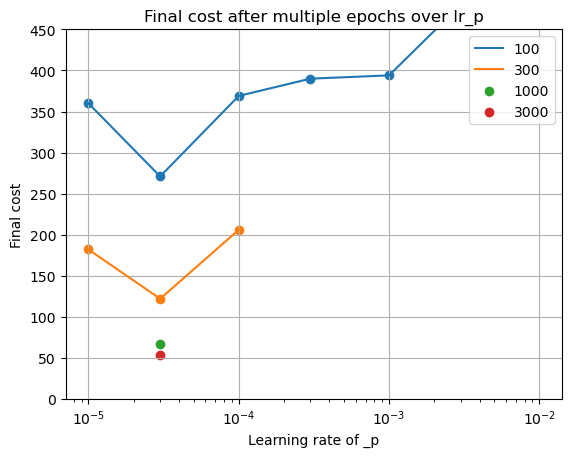

In [75]:
# 2: p sweep

lr_p_list_100 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 1e-2]
fl_list_100 = [360, 271, 369, 390, 394, 574]
plt.plot(lr_p_list_100, fl_list_100, label=100)
plt.scatter(lr_p_list_100, fl_list_100)
lr_p_list_300 = [1e-5, 3e-5, 1e-4]
fl_list_300 = [182, 122, 206]
plt.plot(lr_p_list_300, fl_list_300, label=300)
plt.scatter(lr_p_list_300, fl_list_300)
lr_p_point_1000 = 3e-5
fl_point_1000 = 67
plt.scatter(lr_p_point_1000, fl_point_1000, label=1000)
lr_p_point_3000 = 3e-5
fl_point_3000 = 54
plt.scatter(lr_p_point_3000, fl_point_3000, label=3000)

plt.xscale("log")
plt.grid()
plt.title("Final cost after multiple epochs over lr_p")
plt.ylabel("Final cost")
plt.xlabel("Learning rate of _p")
plt.legend()
plt.ylim(0, 450)
plt.show()

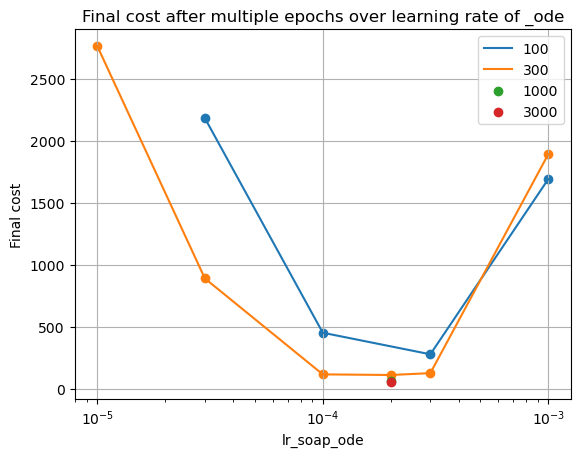

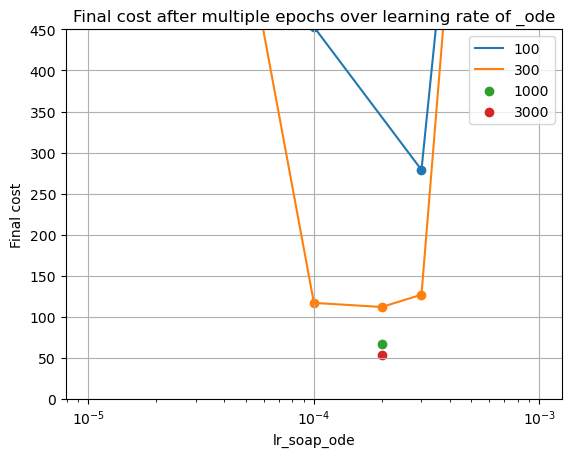

In [77]:
# 3: ode sweep

lr_ode_list_100 = [3e-5, 1e-4, 3e-4, 1e-3]
fl_list_100 = [2184, 453, 279, 1692]
plt.plot(lr_ode_list_100, fl_list_100, label=100)
plt.scatter(lr_ode_list_100, fl_list_100)
lr_ode_list_300 = [1e-5, 3e-5, 1e-4, 2e-4, 3e-4, 1e-3]
fl_list_300 = [2765, 891, 117, 112, 127, 1893]
plt.plot(lr_ode_list_300, fl_list_300, label=300)
plt.scatter(lr_ode_list_300, fl_list_300)
lr_ode_point_1000 = 2e-4
fl_point_1000 = 67
plt.scatter(lr_ode_point_1000, fl_point_1000, label=1000)
lr_ode_point_3000 = 2e-4
fl_point_3000 = 54
plt.scatter(lr_ode_point_3000, fl_point_3000, label=3000)

plt.xscale("log")
plt.grid()
plt.title("Final cost after multiple epochs over learning rate of _ode")
plt.ylabel("Final cost")
plt.xlabel("lr_soap_ode")
plt.legend()
plt.show()

###################################################################
plt.plot(lr_ode_list_100, fl_list_100, label=100)
plt.scatter(lr_ode_list_100, fl_list_100)
plt.plot(lr_ode_list_300, fl_list_300, label=300)
plt.scatter(lr_ode_list_300, fl_list_300)
plt.scatter(lr_ode_point_1000, fl_point_1000, label=1000)
plt.scatter(lr_ode_point_3000, fl_point_3000, label=3000)

plt.xscale("log")
plt.grid()
plt.title("Final cost after multiple epochs over learning rate of _ode")
plt.ylabel("Final cost")
plt.xlabel("lr_soap_ode")
plt.ylim(0, 450)
plt.legend()
plt.show()

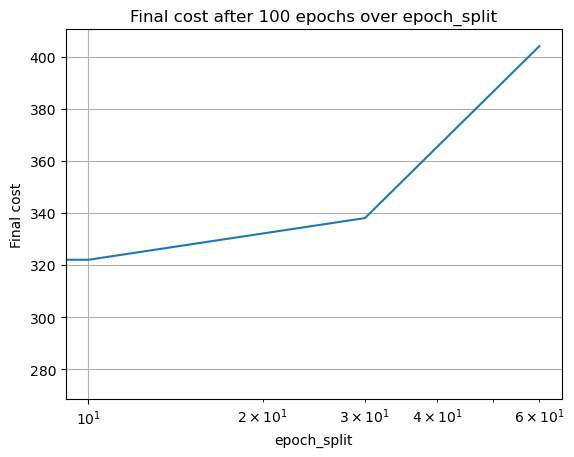

In [33]:
epoch_split_list = [0, 10, 30, 60]
fl_list = [275, 322, 338, 404]
plt.plot(epoch_split_list, fl_list)
plt.xscale("log")
plt.grid()
plt.title("Final cost after 100 epochs over epoch_split")
plt.ylabel("Final cost")
plt.xlabel("epoch_split")
plt.show()

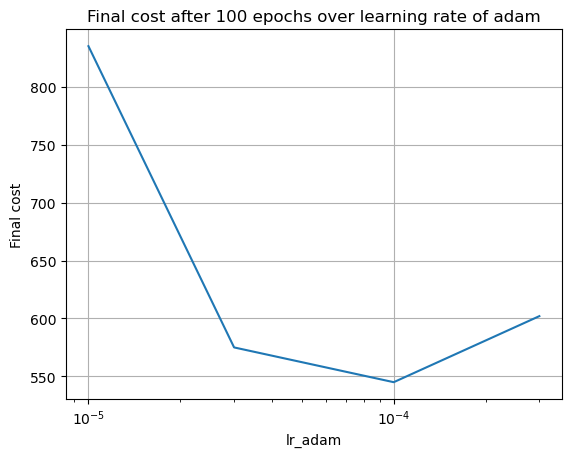

In [35]:
lr_adam_list = [1e-5, 3e-5, 1e-4, 3e-4]
fl_list = [835, 575, 545, 602]
plt.plot(lr_adam_list, fl_list)
plt.xscale("log")
plt.grid()
plt.title("Final cost after 100 epochs over learning rate of adam")
plt.ylabel("Final cost")
plt.xlabel("lr_adam")
plt.show()

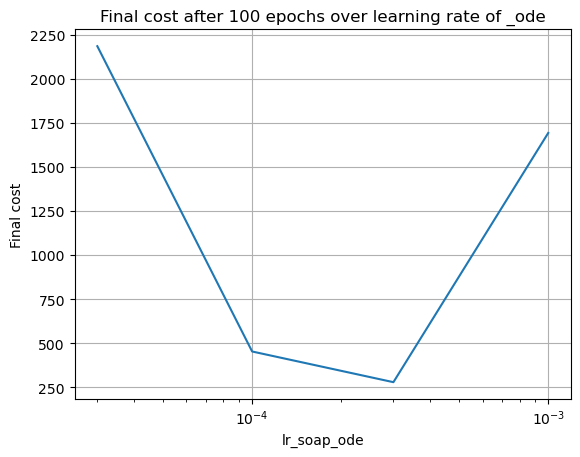

In [36]:
lr_ode_list = [3e-5, 1e-4, 3e-4, 1e-3]
fl_list = [2184, 453, 279, 1692]
plt.plot(lr_ode_list, fl_list)
plt.xscale("log")
plt.grid()
plt.title("Final cost after 100 epochs over learning rate of _ode")
plt.ylabel("Final cost")
plt.xlabel("lr_soap_ode")
plt.show()

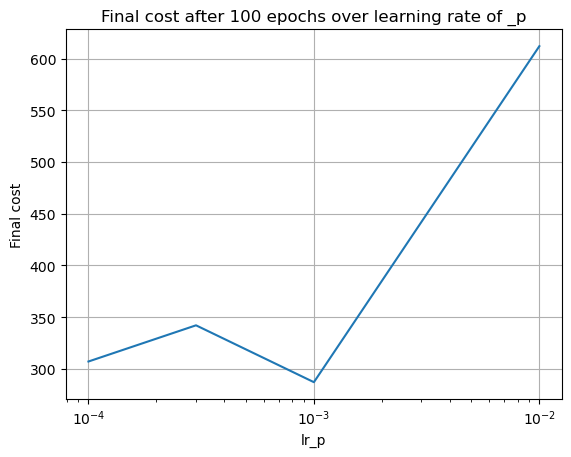

In [34]:
# lr_p sweep

lr_p_list = [1e-4, 3e-4, 1e-3, 1e-2]
fl_list = [307, 342, 287, 612]
plt.plot(lr_p_list, fl_list)
plt.xscale("log")
plt.grid()
plt.title("Final cost after 100 epochs over learning rate of _p")
plt.ylabel("Final cost")
plt.xlabel("lr_p")
plt.show()

### original

In [ ]:
for beta_2 in [0.85, 0.9, 0.999]:
    for beta_1 in [0.85, 0.9, 0.999]:
        betas_ode = (beta_1, beta_2)
        fl_list = []
        lr_ode_set = [1e-2, 1e-3, 1e-5, 1e-7]
        for lr_ode in lr_ode_set:
            model_aif, model_e, model_p, model_ode, total_losses, cost_list = main(seed_value, ps_slice, epochs)
            cost_sum = np.sum(np.array(cost_list), axis=1)[epochs-1]  # Fp+ve+vp+ps losses
            fl_list.append(cost_sum)
        print(fl_list)
        plt.plot(lr_ode_set, fl_list, label="beta_1={}".format(beta_1))
        plt.scatter(lr_ode_set, fl_list)
    plt.title("beta_1={}, beta_2={}".format(beta_1, beta_2))
    plt.xscale("log")
    plt.legend()
    plt.show()

In [ ]:
print(final_loss)
print(final_loss.T)

[[569.39427757 361.31582785 159.66352654  71.60087466]]
[[569.39427757]
 [361.31582785]
 [159.66352654]
 [ 71.60087466]]


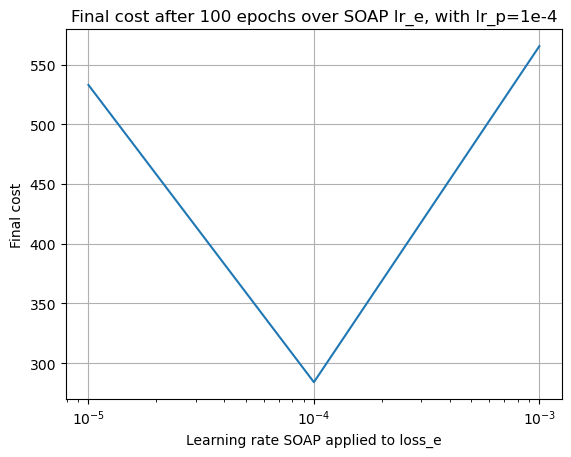

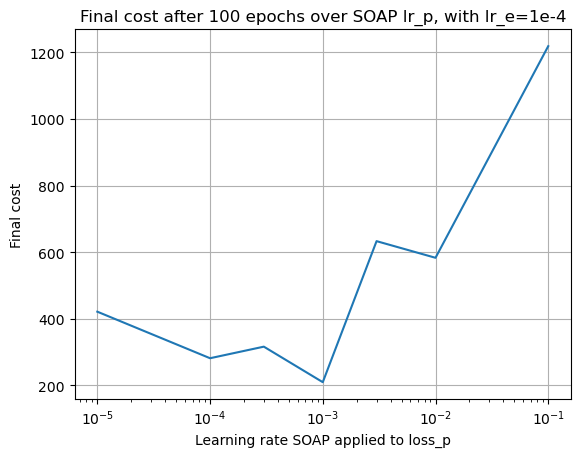

In [ ]:
# sweeping lr_e; lr_p=1e-4
lr_e_set = [1e-3, 1e-4, 1e-5]
final_loss = [565.51356888, 283.98505735, 533.03677654]
plt.plot(lr_e_set, final_loss)
plt.grid()
plt.xscale("log")
plt.title("Final cost after 100 epochs over SOAP lr_e, with lr_p=1e-4")
plt.ylabel("Final cost")
plt.xlabel("Learning rate SOAP applied to loss_e")
plt.show()

# sweeping lr_p; lr_e=1e-4
lr_p_set = [1e-1, 1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 1e-5]
final_loss = [1218.75681305,  582.99230957, 633, 209.27464175, 316, 281.23912215, 421.07547569]
plt.plot(lr_p_set, final_loss)
plt.grid()
plt.xscale("log")
plt.title("Final cost after 100 epochs over SOAP lr_p, with lr_e=1e-4")
plt.ylabel("Final cost")
plt.xlabel("Learning rate SOAP applied to loss_p")
plt.show()

[7361, 9343, 8506.0, 7848.0, 7791, 11611, 583.0, 315, 290, 284, 2145.0, 3336.0, 8275]


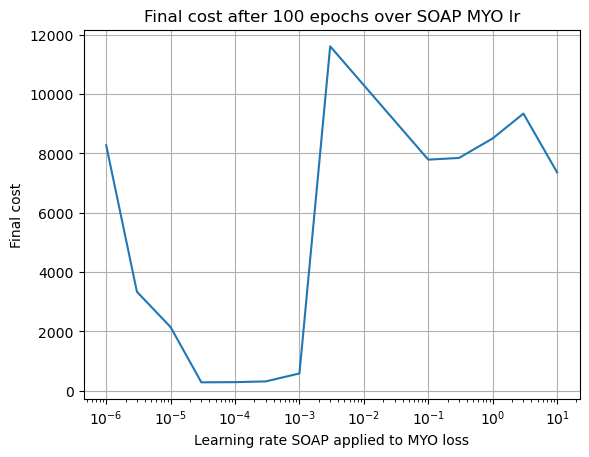

In [ ]:
seed_set = [10, 3, 1, 3e-1, 1e-1, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5, 1e-5, 3e-6, 1e-6]
final_loss_set = [7361, 9343, 8506., 7848., 7791, 11611, 583., 315, 290, 284, 2145., 3336., 8275]
print(final_loss_set)

plt.plot(seed_set, final_loss_set)
plt.xscale("log")
plt.title("Final cost after 100 epochs over SOAP MYO lr")
plt.ylabel("Final cost")
plt.xlabel("Learning rate SOAP applied to MYO loss")
plt.grid()
#plt.xticks([3e-5, 1e-4, 3e-4, 1e-3], [3e-5, 1e-4, 3e-4, 1e-3])

In [ ]:
print(cost_sum[99])

523.7292819023132


[2467, 571, 524, 550, 2485]


([<matplotlib.axis.XTick at 0x270e47ef6e0>,
 [Text(3e-05, 0, '3e-05'),
  Text(0.0001, 0, '0.0001'),
  Text(0.0003, 0, '0.0003'),
  Text(0.001, 0, '0.001')])

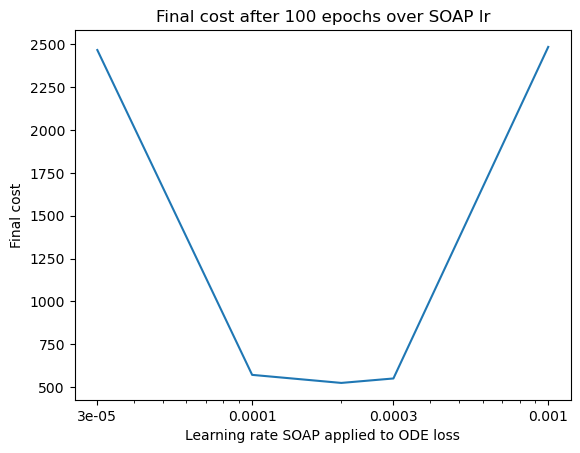

In [ ]:
final_loss_99 = [2467, 571, 524, 550, 2485]
print(final_loss_99)

plt.plot([3e-5, 1e-4, 2e-4, 3e-4, 1e-3], final_loss_99)
plt.xscale("log")
plt.title("Final cost after 100 epochs over SOAP lr")
plt.ylabel("Final cost")
plt.xlabel("Learning rate SOAP applied to ODE loss")
plt.xticks([3e-5, 1e-4, 3e-4, 1e-3], [3e-5, 1e-4, 3e-4, 1e-3])

(1000,)
63.14186239242554


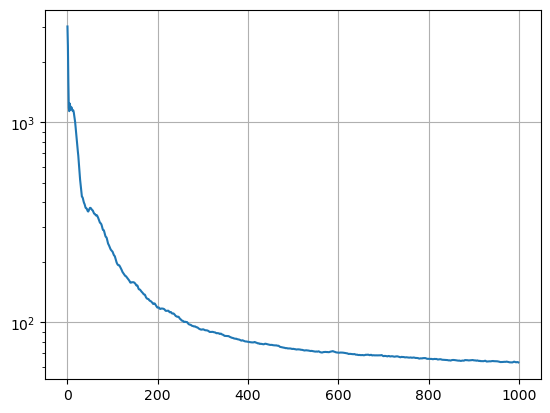

In [ ]:
print(cost_sum.shape)
plt.plot(cost_sum)
print(cost_sum[-1])
plt.grid()
plt.yscale("log")

[[1592.]
 [1472.]
 [1145.]]


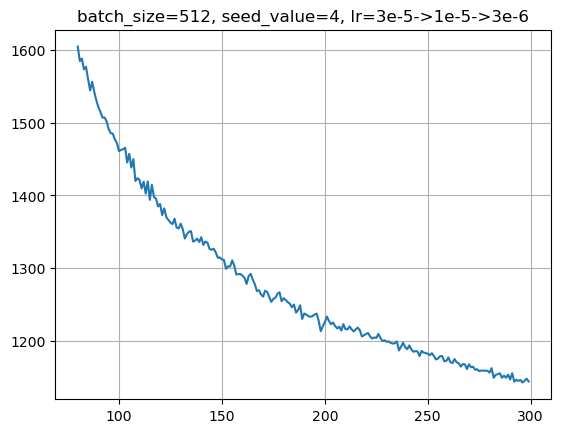

In [ ]:
print(np.around(final_loss, 0).T)
y_data = cost_sum

plt.plot(np.arange(80, len(cost_sum[80:])+80), cost_sum[80:])
plt.title("batch_size=512, seed_value=4, lr=3e-5->1e-5->3e-6")
plt.grid()

In [ ]:
plt.plot(y_data)

NameError: name 'y_data' is not defined

In [ ]:
#####################3 model losses saving

#np.save("cost_sum_4_3000_512_2lr_smooth.npy", y_data)

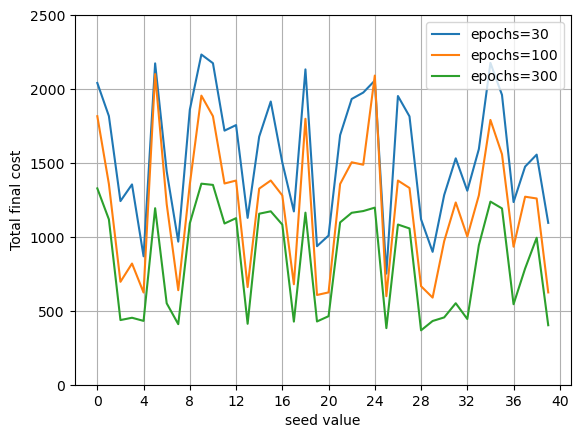

In [31]:
# DATA: variability for 1A model, meaning convolutional loss, MSE criterion, and Adam optimizer

seed_values = np.arange(0, 40)

fl_09_30 = [2041.0342865, 1817.16262817, 1242.08413696, 1354.82438278, 868.68933773, 2173.71059036, 1443.17158699, 
 967.76900673, 1860.00162888, 2233.49024582]
fl_30 = [2174.85052109, 1718.53709221, 1756.21317101, 1128.64660645, 1678.07248688, 1915.58394241, 1503.31450081, 
         1172.30664635, 2132.95944595, 936.89330196, 1009.01616096, 1688.163908, 1932.81077003, 1976.22146988, 
         2057.31811905, 751.52515507, 1952.78017426, 1815.1165123, 1118.79101562, 898.78807259, 1283.07074928, 
         1531.24822998, 1312.23288345, 1593.91981125, 2176.68587112, 1960.55641556, 1235.39776421, 1475.31562996,
           1556.41758347, 1094.900238040]
fl_30_full = []
for list_ in [fl_09_30, fl_30]:
    for elt in list_:
        fl_30_full.append(elt)

fl_09_100 = [1816.25112915, 1357.7066021, 696.05937767, 819.69483185, 623.55674791, 2101.42475891, 1221.73070765,
 639.43999147, 1355.80723572, 1955.44471359]
fl_100 = [1816.37981796, 1361.12882423, 1380.97376728, 660.43295097, 1326.45242882, 1381.27276039, 1280.38038254, 
          679.48173332, 1798.88397598, 607.05668926, 624.50019979, 1357.62481689, 1504.68316364, 1488.04299641, 
          2091.13491821, 598.82614899, 1381.11494637, 1330.73468542, 666.3400631, 589.26685095, 970.80098724, 
          1232.74098587, 1002.48580265, 1281.10715389, 1791.06262779, 1559.13994026, 933.30466652, 1271.71178436, 
          1259.76792669, 624.33000898]
fl_100_full = []
for list_ in [fl_09_100, fl_100]:
    for elt in list_:
        fl_100_full.append(elt)

fl_09_300 = [1328.03604698, 1118.44868326, 437.37966967, 452.99571276, 431.74449158, 1193.92588806, 550.72154903,
            409.59411526, 1091.97665167, 1359.91154289]
fl_300 = [1351.58122158, 1090.427526, 1126.5374136, 412.10630322, 1156.6332922, 1172.93819904, 1082.95396781, 
          426.89445639, 1163.884974, 427.87793064, 463.51944828, 1097.9771328, 1162.97265244, 1174.6751585, 
          1197.76004601, 382.79889584, 1083.54032469, 1057.12874031, 367.89570999, 431.03493023, 455.31325626, 
          551.18302345, 444.49038601, 943.78087902, 1238.63262177, 1192.540977, 544.3891964, 786.04391098, 
          994.06250906, 402.4422245]
fl_300_full = []
for list_ in [fl_09_300, fl_300]:
    for elt in list_:
        fl_300_full.append(elt)

seed_values_1000_a = [2,3,4,7,13,17,19]
fl_1000_a = [ 254.,  270.,  271.,  296.,  263.,  274.,  261.]
seed_values_1000_b = [20, 25, 28, 29, 30, 32, 39]
fl_1000_b = [ 264.,  272.,  274.,  246.,  260.,  239.,  260.]
seed_values_1000 = [2,3,4,7,13,17,19, 20, 25, 28, 29, 30, 32, 39]
fl_1000_full = []
for list_ in [fl_1000_a, fl_1000_b]:
    for elt in list_:
        fl_1000_full.append(elt)

plt.plot(seed_values, fl_30_full, label="epochs=30")
plt.plot(seed_values, fl_100_full, label="epochs=100" )
plt.plot(seed_values, fl_300_full, label="epochs=300")
#plt.plot(seed_values_1000, fl_1000_full, label="epochs=1000")
#plt.scatter(seed_values_1000, fl_1000_full, label="epochs=1000", c="red")
# plt.scatter(4, 166., label="epochs=3000", c="red")

plt.legend()
plt.grid()
plt.xlabel("seed value")
plt.ylabel("Total final cost")
plt.ylim((0, 2500))
plt.xticks(np.arange(0, 41, 4))
plt.show()

In [ ]:
print(np.mean(np.array(fl_300_full)))

NameError: name 'fl_300_full' is not defined

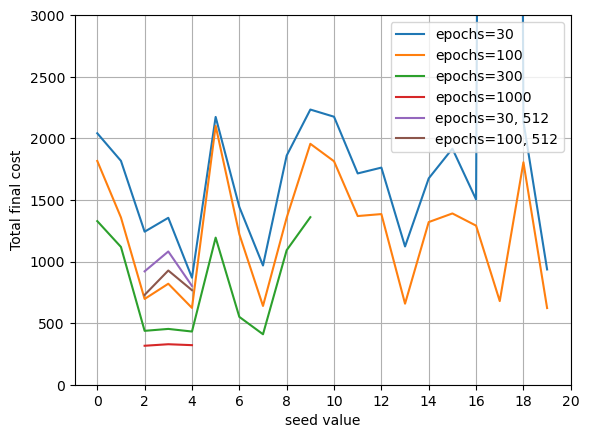

In [ ]:
################### 0 -> 9
seed_values_09 = np.arange(0, 10)
#final losses for seed values ind_start to ind_end; for different amount of epochs 
fl_09_30 = [2041.0342865, 1817.16262817, 1242.08413696, 1354.82438278, 868.68933773, 2173.71059036, 1443.17158699, 
 967.76900673, 1860.00162888, 2233.49024582]
fl_09_100 = [1816.25112915, 1357.7066021, 696.05937767, 819.69483185, 623.55674791, 2101.42475891, 1221.73070765,
 639.43999147, 1355.80723572, 1955.44471359]

#################### 10 -> 19
seed_values_1019 = np.arange(10, 20)
fl_1019_30 = [2175.31947708, 1714.9962368, 1762.28892136, 1122.32619476, 1674.9864006, 1916.16172409, 1503.8421278, 
              41175.31441307, 2135.32325745, 935.67053986]
fl_1019_100 = [1813.71325874, 1369.09678745, 1385.09143639, 657.89869833, 1320.25049257, 1390.22990227, 1291.18359041, 
               678.79915285, 1805.42628288, 622.24767542]

################## extra: 300 epochs for seed values 0-> 9
seed_values_extra = np.arange(0, 10)
fl_09_300 = [1328.03604698, 1118.44868326, 437.37966967, 452.99571276, 431.74449158, 1193.92588806, 550.72154903,
            409.59411526, 1091.97665167, 1359.91154289]

################ extra_2: 1000 epochs for seed values 2 -> 4
seed_values_extra_2 = np.arange(2, 5)
fl_24_1000 = [ 316.28596449,  328.60443377,  321.14710283]

################### concatenating lists into single array
seed_values = []
for list_ in [seed_values_09, seed_values_1019]:
    for elt in list_:
        seed_values.append(elt)
fl_30_full = []
for list_ in [fl_09_30, fl_1019_30]:
    for elt in list_:
        fl_30_full.append(elt)
fl_100_full = []
for list_ in [fl_09_100, fl_1019_100]:
    for elt in list_:
        fl_100_full.append(elt)

###################### adding batch size 512 plots

seed_values_512 = [2,3,4]
fl_24_30_512 = [ 920.33959389, 1081.44276428, 802.0500536 ]
fl_24_100_512 = [ 729.18639851,  926.94294739,  767.29029942]

#################### finishing plot

plt.plot(seed_values, fl_30_full, label="epochs=30")
plt.plot(seed_values, fl_100_full, label="epochs=100" )
plt.plot(seed_values_extra, fl_09_300, label="epochs=300")
plt.plot(seed_values_extra_2, fl_24_1000, label="epochs=1000")
plt.plot(seed_values_512, fl_24_30_512, label="epochs=30, 512")
plt.plot(seed_values_512, fl_24_100_512, label="epochs=100, 512")

plt.legend()
plt.grid()
plt.xlabel("seed value")
plt.ylabel("Total final cost")
plt.ylim((0, 3000))
plt.xticks(np.arange(0, 21, 2))
plt.show()